# Projet – Étude de marché internationale
## La poule qui chante

### Notebook 1 – Préparation, nettoyage et exploration des données

**Objectif du projet :**  
Identifier des groupes de pays susceptibles de représenter des marchés intéressants
pour le développement international de l'entreprise française
*La poule qui chante*, spécialisée dans l'élevage et la vente de poulets biologiques.

Ce premier notebook est consacré à :
- l'importation des données ;
- leur compréhension ;
- leur préparation et leur nettoyage ;
- la création de nouvelles variables ;
- la fusion des différentes sources ;
- l'analyse exploratoire des données.

Les données principales proviennent de la FAO et seront complétées par des
indicateurs socio-économiques pertinents issus de sources open data.

## 1. Importation des bibliothèques Python

### 1.1 Importation des bibliothèques Python

Cette étape permet d'importer les bibliothèques nécessaires à la manipulation, à l'analyse et à la visualisation des données.

In [1]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt

# Gestion des avertissements
import warnings
warnings.filterwarnings("ignore")

# Options d'affichage pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## 2. Importation des données

Deux jeux de données sont utilisés pour débuter l'analyse :

- les données de disponibilité alimentaire de la FAO pour l'année 2017 ;
- les données de population couvrant la période 2000 à 2018.

L'objectif de cette étape est de charger les fichiers et de vérifier leur structure avant toute opération de nettoyage.

### 2.1 Chargement des jeux de données

Les fichiers de disponibilité alimentaire et de population sont importés dans des DataFrames pandas afin de pouvoir être explorés, nettoyés et analysés.

In [2]:
# Importation des données FAO
df_dispo = pd.read_csv(
    "DisponibiliteAlimentaire_2017.csv",
    encoding="utf-8"
)

# Importation des données de population
df_population = pd.read_csv(
    "Population_2000_2018.csv",
    encoding="utf-8"
)

print("Données importées avec succès.")

Données importées avec succès.


## 3. Exploration initiale des jeux de données

Avant de procéder au nettoyage, une première exploration des données est réalisée afin de comprendre leur structure, leurs dimensions et les variables disponibles.

### 3.1 Vérification des dimensions des jeux de données

Cette étape permet de connaître le nombre de lignes et de colonnes de chaque jeu de données avant le nettoyage.

In [3]:
# Dimensions des jeux de données

print("Dimensions du fichier Disponibilité Alimentaire :", df_dispo.shape)
print("Dimensions du fichier Population :", df_population.shape)

Dimensions du fichier Disponibilité Alimentaire : (176600, 14)
Dimensions du fichier Population : (4411, 15)


### 3.2 Identification des variables disponibles

Les noms des colonnes sont examinés afin d'identifier les variables disponibles et de comprendre la structure des deux jeux de données.

In [4]:
# Affichage des noms de colonnes

print("Colonnes du fichier Disponibilité Alimentaire :")
print(df_dispo.columns.tolist())

print("\nColonnes du fichier Population :")
print(df_population.columns.tolist())

Colonnes du fichier Disponibilité Alimentaire :
['Code Domaine', 'Domaine', 'Code zone', 'Zone', 'Code Élément', 'Élément', 'Code Produit', 'Produit', 'Code année', 'Année', 'Unité', 'Valeur', 'Symbole', 'Description du Symbole']

Colonnes du fichier Population :
['Code Domaine', 'Domaine', 'Code zone', 'Zone', 'Code Élément', 'Élément', 'Code Produit', 'Produit', 'Code année', 'Année', 'Unité', 'Valeur', 'Symbole', 'Description du Symbole', 'Note']


### 3.3 Aperçu des données de disponibilité alimentaire

Les premières lignes du fichier sont affichées afin de comprendre son organisation et d'identifier les informations disponibles sur la disponibilité alimentaire.

In [5]:
# Aperçu des premières lignes du fichier Disponibilité Alimentaire

df_dispo.head()

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.0,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.0,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.0,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.0,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.0,S,Données standardisées


### 3.4 Aperçu des données de population

Les premières lignes du fichier de population sont affichées afin de vérifier sa structure et les informations disponibles pour chaque pays.

In [6]:
# Aperçu des premières lignes du fichier Population

df_population.head()

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole,Note
0,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2000,2000,1000 personnes,20779.953,X,Sources internationales sûres,NaN
1,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2001,2001,1000 personnes,21606.988,X,Sources internationales sûres,NaN
2,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2002,2002,1000 personnes,22600.770,X,Sources internationales sûres,NaN
3,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2003,2003,1000 personnes,23680.871,X,Sources internationales sûres,NaN
4,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2004,2004,1000 personnes,24726.684,X,Sources internationales sûres,NaN


### 3.5 Structure du fichier de disponibilité alimentaire

Cette étape permet de vérifier les types de données, le nombre d'observations et la présence éventuelle de valeurs manquantes.

In [7]:
# Informations générales sur le fichier Disponibilité Alimentaire

df_dispo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 176600 entries, 0 to 176599
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Code Domaine            176600 non-null  object 
 1   Domaine                 176600 non-null  object 
 2   Code zone               176600 non-null  int64  
 3   Zone                    176600 non-null  object 
 4   Code Élément            176600 non-null  int64  
 5   Élément                 176600 non-null  object 
 6   Code Produit            176600 non-null  int64  
 7   Produit                 176600 non-null  object 
 8   Code année              176600 non-null  int64  
 9   Année                   176600 non-null  int64  
 10  Unité                   176600 non-null  object 
 11  Valeur                  176600 non-null  float64
 12  Symbole                 176600 non-null  object 
 13  Description du Symbole  176600 non-null  object 
dtypes: float64(1), int64

### 3.6 Structure du fichier de population

L'analyse de la structure du fichier permet de contrôler les types de variables ainsi que le nombre de valeurs renseignées pour chaque colonne.

In [8]:
# Informations générales sur le fichier Population

df_population.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4411 entries, 0 to 4410
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Code Domaine            4411 non-null   object 
 1   Domaine                 4411 non-null   object 
 2   Code zone               4411 non-null   int64  
 3   Zone                    4411 non-null   object 
 4   Code Élément            4411 non-null   int64  
 5   Élément                 4411 non-null   object 
 6   Code Produit            4411 non-null   int64  
 7   Produit                 4411 non-null   object 
 8   Code année              4411 non-null   int64  
 9   Année                   4411 non-null   int64  
 10  Unité                   4411 non-null   object 
 11  Valeur                  4411 non-null   float64
 12  Symbole                 4411 non-null   object 
 13  Description du Symbole  4411 non-null   object 
 14  Note                    258 non-null    

## 4. Diagnostic de la qualité des données

Avant le nettoyage, la qualité des données est évaluée en recherchant notamment
les valeurs manquantes et les éventuels doublons.

Cette étape permet de justifier les traitements qui seront appliqués par la suite.

### 4.1 Identification des valeurs manquantes

Cette étape permet de détecter les variables contenant des données manquantes dans les deux jeux de données avant leur utilisation dans l'analyse.

In [9]:
# Nombre de valeurs manquantes par colonne

print("Valeurs manquantes - Disponibilité Alimentaire :")
print(df_dispo.isnull().sum())

print("\nValeurs manquantes - Population :")
print(df_population.isnull().sum())

Valeurs manquantes - Disponibilité Alimentaire :
Code Domaine              0
Domaine                   0
Code zone                 0
Zone                      0
Code Élément              0
Élément                   0
Code Produit              0
Produit                   0
Code année                0
Année                     0
Unité                     0
Valeur                    0
Symbole                   0
Description du Symbole    0
dtype: int64

Valeurs manquantes - Population :
Code Domaine                 0
Domaine                      0
Code zone                    0
Zone                         0
Code Élément                 0
Élément                      0
Code Produit                 0
Produit                      0
Code année                   0
Année                        0
Unité                        0
Valeur                       0
Symbole                      0
Description du Symbole       0
Note                      4153
dtype: int64


### 4.2 Analyse du taux de valeurs manquantes

Le pourcentage de valeurs manquantes est calculé afin d'évaluer leur importance et de déterminer le traitement le plus approprié.

In [10]:
# Pourcentage de valeurs manquantes dans le fichier Population

pourcentage_manquantes = (
    df_population.isnull().sum() / len(df_population) * 100
).round(2)

print(pourcentage_manquantes)

Code Domaine               0.00
Domaine                    0.00
Code zone                  0.00
Zone                       0.00
Code Élément               0.00
Élément                    0.00
Code Produit               0.00
Produit                    0.00
Code année                 0.00
Année                      0.00
Unité                      0.00
Valeur                     0.00
Symbole                    0.00
Description du Symbole     0.00
Note                      94.15
dtype: float64


### 4.3 Traitement de la colonne `Note`

La colonne `Note` du fichier Population présente **94,15 % de valeurs manquantes**.

Cette variable contient des informations complémentaires ponctuelles et n'est pas nécessaire
pour l'analyse quantitative des pays. Compte tenu de son taux très élevé de valeurs manquantes
et de sa faible utilité pour les analyses statistiques prévues, elle est supprimée du jeu de données.

Les autres variables ne présentent aucune valeur manquante.

In [11]:
# Suppression de la colonne Note

df_population = df_population.drop(columns=["Note"])

print("Colonne 'Note' supprimée.")
print("Nombre de colonnes restantes :", df_population.shape[1])

Colonne 'Note' supprimée.
Nombre de colonnes restantes : 14


### 4.4 Recherche des lignes dupliquées

La présence de doublons est vérifiée afin d'éviter que certaines observations soient comptabilisées plusieurs fois et biaisent les résultats de l'analyse.

In [12]:
# Recherche des lignes dupliquées

doublons_dispo = df_dispo.duplicated().sum()
doublons_population = df_population.duplicated().sum()

print("Nombre de doublons - Disponibilité Alimentaire :", doublons_dispo)
print("Nombre de doublons - Population :", doublons_population)

Nombre de doublons - Disponibilité Alimentaire : 0
Nombre de doublons - Population : 0


## 5. Préparation des données de population

Les données de disponibilité alimentaire portent sur l'année 2017.

Afin de garantir la cohérence temporelle entre les différentes sources, seules les données
de population correspondant à l'année 2017 sont conservées pour la suite de l'analyse.

### 5.1 Sélection des données de population pour 2017

Les données de population sont filtrées sur l'année 2017 afin d'assurer la cohérence temporelle avec les données de disponibilité alimentaire.

In [13]:
# Sélection des données de population pour l'année 2017

population_2017 = df_population[df_population["Année"] == 2017].copy()

print("Nombre de lignes avant filtrage :", len(df_population))
print("Nombre de lignes après sélection de 2017 :", len(population_2017))

Nombre de lignes avant filtrage : 4411
Nombre de lignes après sélection de 2017 : 236


### 5.2 Vérification des pays disponibles en 2017

Cette étape permet d'identifier le nombre de zones géographiques disponibles après le filtrage des données de population sur l'année 2017.

In [14]:
# Vérification des zones présentes en 2017

print("Nombre de zones en 2017 :", population_2017["Zone"].nunique())

print("\nExemples de zones :")
print(population_2017["Zone"].unique()[:30])

Nombre de zones en 2017 : 236

Exemples de zones :
['Afghanistan' 'Afrique du Sud' 'Albanie' 'Algérie' 'Allemagne' 'Andorre'
 'Angola' 'Anguilla' 'Antigua-et-Barbuda' 'Antilles néerlandaises (ex)'
 'Arabie saoudite' 'Argentine' 'Arménie' 'Aruba' 'Australie' 'Autriche'
 'Azerbaïdjan' 'Bahamas' 'Bahreïn' 'Bangladesh' 'Barbade' 'Bélarus'
 'Belgique' 'Belize' 'Bénin' 'Bermudes' 'Bhoutan'
 'Bolivie (État plurinational de)' 'Bonaire, Saint-Eustache et Saba'
 'Bosnie-Herzégovine']


### 5.3 Vérification de l'unité de mesure de la population

L'unité utilisée dans le fichier est contrôlée avant toute conversion afin de garantir une interprétation correcte des données de population.

In [15]:
# Vérification des unités utilisées pour la population en 2017

print("Unités présentes :")
print(population_2017["Unité"].value_counts())

Unités présentes :
Unité
1000 personnes    236
Name: count, dtype: int64


### 5.4 Conversion de la population en nombre d'habitants

Les valeurs étant exprimées en milliers de personnes, elles sont multipliées par 1 000 afin d'obtenir la population réelle en nombre d'habitants.

In [16]:
# Conversion de la population en nombre d'habitants

population_2017["Population"] = population_2017["Valeur"] * 1000

# Vérification
population_2017[["Zone", "Valeur", "Unité", "Population"]].head()

,Zone,Valeur,Unité,Population
17,Afghanistan,36296.113,1000 personnes,36296113.0
36,Afrique du Sud,57009.756,1000 personnes,57009756.0
55,Albanie,2884.169,1000 personnes,2884169.0
74,Algérie,41389.189,1000 personnes,41389189.0
93,Allemagne,82658.409,1000 personnes,82658409.0


### 5.5 Création de la table de population nettoyée

Seules les variables nécessaires à la suite de l'analyse sont conservées afin d'obtenir une table de population simplifiée et exploitable.

In [17]:
# Création d'une table simplifiée pour la population

population_clean = population_2017[
    ["Code zone", "Zone", "Population"]
].copy()

# Réinitialisation de l'index
population_clean.reset_index(drop=True, inplace=True)

print("Dimensions de la table Population nettoyée :", population_clean.shape)

population_clean.head()

Dimensions de la table Population nettoyée : (236, 3)


,Code zone,Zone,Population
0,2,Afghanistan,36296113.0
1,202,Afrique du Sud,57009756.0
2,3,Albanie,2884169.0
3,4,Algérie,41389189.0
4,79,Allemagne,82658409.0


## 6. Préparation des données de disponibilité alimentaire

L'étude porte sur le potentiel de développement international d'une entreprise spécialisée
dans la production et la vente de poulets biologiques.

Les données alimentaires de la FAO contiennent de nombreux produits. Il est donc nécessaire
d'identifier les produits relatifs à la volaille avant de sélectionner les variables pertinentes
pour l'analyse.

### 6.1 Identification des produits relatifs à la volaille

Une recherche est effectuée dans la variable `Produit` afin d'identifier précisément le libellé correspondant à la viande de volaille dans les données FAO.

In [18]:
# Recherche des produits relatifs à la volaille

produits_volaille = sorted(
    df_dispo.loc[
        df_dispo["Produit"].str.contains(
            "volaille",
            case=False,
            na=False
        ),
        "Produit"
    ].unique()
)

print("Produits contenant le terme 'volaille' :")
print(produits_volaille)

Produits contenant le terme 'volaille' :
['Viande de Volailles']


### 6.2 Sélection des données concernant la viande de volaille

Les observations correspondant à la viande de volaille sont isolées afin de construire le jeu de données spécifique à notre problématique d'analyse.

In [19]:
# Sélection des données relatives à la viande de volailles

volaille = df_dispo[
    df_dispo["Produit"] == "Viande de Volailles"
].copy()

print("Nombre de lignes relatives à la viande de volailles :", len(volaille))

print("\nÉléments disponibles :")
print(sorted(volaille["Élément"].unique()))

Nombre de lignes relatives à la viande de volailles : 2061

Éléments disponibles :
['Alimentation pour touristes', 'Aliments pour animaux', 'Autres utilisations (non alimentaire)', 'Disponibilité alimentaire (Kcal/personne/jour)', 'Disponibilité alimentaire en quantité (kg/personne/an)', 'Disponibilité de matière grasse en quantité (g/personne/jour)', 'Disponibilité de protéines en quantité (g/personne/jour)', 'Disponibilité intérieure', 'Exportations - Quantité', 'Importations - Quantité', 'Nourriture', 'Pertes', 'Production', 'Résidus', 'Semences', 'Traitement', 'Variation de stock']


### 6.3 Sélection des indicateurs pertinents et contrôle des unités

Les indicateurs nécessaires à l'analyse sont identifiés et leurs unités sont vérifiées afin de distinguer notamment les kilogrammes par personne des volumes exprimés en milliers de tonnes.

In [20]:
# Indicateurs FAO retenus pour l'analyse du marché de la volaille

elements_retenus = [
    "Production",
    "Importations - Quantité",
    "Exportations - Quantité",
    "Disponibilité intérieure",
    "Disponibilité alimentaire en quantité (kg/personne/an)"
]

# Vérification des unités associées à chaque indicateur
unites_volaille = (
    volaille[volaille["Élément"].isin(elements_retenus)]
    [["Élément", "Unité"]]
    .drop_duplicates()
    .sort_values("Élément")
)

unites_volaille

,Élément,Unité
658,Disponibilité alimentaire en quantité (kg/pers...,kg
654,Disponibilité intérieure,Milliers de tonnes
1707,Exportations - Quantité,Milliers de tonnes
652,Importations - Quantité,Milliers de tonnes
651,Production,Milliers de tonnes


### 6.4 Restructuration des données de volaille

Les données sont restructurées afin d'obtenir une ligne par pays et une colonne par indicateur. Cette organisation facilite les analyses statistiques et la future segmentation des pays.

### Restructuration des données sur la volaille

Les données FAO sont initialement organisées au format long : plusieurs lignes peuvent
correspondre à une même zone selon l'indicateur considéré.

Pour préparer la fusion des sources et les futures analyses statistiques, les données sont
restructurées afin d'obtenir une ligne par zone et une colonne par indicateur.

In [21]:
# Sélection des indicateurs retenus

volaille_selection = volaille[
    volaille["Élément"].isin(elements_retenus)
].copy()

# Passage du format long au format large
volaille_pivot = volaille_selection.pivot_table(
    index=["Code zone", "Zone"],
    columns="Élément",
    values="Valeur",
    aggfunc="first"
).reset_index()

# Suppression du nom de l'axe des colonnes
volaille_pivot.columns.name = None

print("Dimensions de la table restructurée :", volaille_pivot.shape)

volaille_pivot.head()

Dimensions de la table restructurée : (172, 7)


,Code zone,Zone,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Production
0,1,Arménie,16.06,47.0,0.0,35.0,11.0
1,2,Afghanistan,1.53,57.0,NaN,29.0,28.0
2,3,Albanie,16.36,47.0,0.0,38.0,13.0
3,4,Algérie,6.38,277.0,0.0,2.0,275.0
4,7,Angola,10.56,319.0,0.0,277.0,42.0


### 6.5 Analyse des valeurs manquantes après restructuration

La présence de valeurs manquantes est vérifiée après la restructuration afin d'identifier les indicateurs nécessitant un traitement avant la fusion des données.

In [22]:
# Vérification des valeurs manquantes après restructuration

valeurs_manquantes_volaille = volaille_pivot.isnull().sum()

print("Valeurs manquantes par variable :")
print(valeurs_manquantes_volaille)

print("\nPourcentage de valeurs manquantes :")
print(
    (volaille_pivot.isnull().mean() * 100).round(2)
)

Valeurs manquantes par variable :
Code zone                                                  0
Zone                                                       0
Disponibilité alimentaire en quantité (kg/personne/an)     0
Disponibilité intérieure                                   2
Exportations - Quantité                                   37
Importations - Quantité                                    2
Production                                                 4
dtype: int64

Pourcentage de valeurs manquantes :
Code zone                                                  0.00
Zone                                                       0.00
Disponibilité alimentaire en quantité (kg/personne/an)     0.00
Disponibilité intérieure                                   1.16
Exportations - Quantité                                   21.51
Importations - Quantité                                    1.16
Production                                                 2.33
dtype: float64


### 6.6 Traitement des valeurs manquantes des indicateurs commerciaux

Les valeurs manquantes des variables de production, d'importation, d'exportation et de disponibilité intérieure sont traitées afin d'obtenir un jeu de données exploitable pour la suite de l'analyse.

In [23]:
# Traitement des valeurs manquantes des indicateurs de volaille

colonnes_a_completer = [
    "Disponibilité intérieure",
    "Exportations - Quantité",
    "Importations - Quantité",
    "Production"
]

volaille_pivot[colonnes_a_completer] = (
    volaille_pivot[colonnes_a_completer].fillna(0)
)

# Vérification après traitement
print("Valeurs manquantes après traitement :")
print(volaille_pivot.isnull().sum())

Valeurs manquantes après traitement :
Code zone                                                 0
Zone                                                      0
Disponibilité alimentaire en quantité (kg/personne/an)    0
Disponibilité intérieure                                  0
Exportations - Quantité                                   0
Importations - Quantité                                   0
Production                                                0
dtype: int64


### 7. Construction du jeu de données d'analyse

### 7.1 Fusion des données de population et de volaille

Les données de population sont fusionnées avec les indicateurs relatifs à la volaille à partir du code pays afin de constituer une base d'analyse commune.

In [24]:
# Fusion des données de volaille avec la population 2017

data_final = pd.merge(
    volaille_pivot,
    population_clean,
    on="Code zone",
    how="left",
    suffixes=("", "_population")
)

print("Dimensions avant fusion :", volaille_pivot.shape)
print("Dimensions après fusion :", data_final.shape)

data_final.head()

Dimensions avant fusion : (172, 7)
Dimensions après fusion : (172, 9)


,Code zone,Zone,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Production,Zone_population,Population
0,1,Arménie,16.06,47.0,0.0,35.0,11.0,Arménie,2944791.0
1,2,Afghanistan,1.53,57.0,0.0,29.0,28.0,Afghanistan,36296113.0
2,3,Albanie,16.36,47.0,0.0,38.0,13.0,Albanie,2884169.0
3,4,Algérie,6.38,277.0,0.0,2.0,275.0,Algérie,41389189.0
4,7,Angola,10.56,319.0,0.0,277.0,42.0,Angola,29816766.0


### 7.2 Contrôle de la qualité de la fusion

Cette vérification permet de s'assurer que chaque pays du jeu de données dispose bien d'une information de population après la fusion.

In [25]:
# Vérification de la qualité de la fusion avec la population

population_manquante = data_final["Population"].isnull().sum()

print("Nombre de populations manquantes :", population_manquante)

# Affichage des zones sans correspondance éventuelle
if population_manquante > 0:
    print("\nZones sans population correspondante :")
    print(
        data_final.loc[
            data_final["Population"].isnull(),
            ["Code zone", "Zone"]
        ]
    )
else:
    print("Toutes les zones disposent d'une population.")

Nombre de populations manquantes : 0
Toutes les zones disposent d'une population.


### 7.3 Nettoyage du jeu de données fusionné

Les colonnes devenues redondantes après la fusion sont supprimées afin d'obtenir une table d'analyse plus claire et plus cohérente.

In [26]:
# Nettoyage de la table après fusion

data_final = data_final.drop(columns=["Zone_population"])

print("Dimensions après nettoyage :", data_final.shape)

data_final.head()

Dimensions après nettoyage : (172, 8)


,Code zone,Zone,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Production,Population
0,1,Arménie,16.06,47.0,0.0,35.0,11.0,2944791.0
1,2,Afghanistan,1.53,57.0,0.0,29.0,28.0,36296113.0
2,3,Albanie,16.36,47.0,0.0,38.0,13.0,2884169.0
3,4,Algérie,6.38,277.0,0.0,2.0,275.0,41389189.0
4,7,Angola,10.56,319.0,0.0,277.0,42.0,29816766.0


### 8. Création des indicateurs d'aide à la décision

### 8.1 Calcul du taux de dépendance aux importations

Le taux de dépendance aux importations mesure le poids des importations par rapport à la disponibilité intérieure de volaille. Cet indicateur permet d'identifier les marchés fortement dépendants de l'approvisionnement extérieur.

In [27]:
# Création du taux de dépendance aux importations

data_final["Taux_dependance_importations"] = (
    data_final["Importations - Quantité"]
    / data_final["Disponibilité intérieure"]
    * 100
)

# Vérification
data_final[
    [
        "Zone",
        "Disponibilité intérieure",
        "Importations - Quantité",
        "Taux_dependance_importations"
    ]
].head(10)

,Zone,Disponibilité intérieure,Importations - Quantité,Taux_dependance_importations
0,Arménie,47.0,35.0,74.468085
1,Afghanistan,57.0,29.0,50.877193
2,Albanie,47.0,38.0,80.851064
3,Algérie,277.0,2.0,0.722022
4,Angola,319.0,277.0,86.833856
5,Antigua-et-Barbuda,7.0,7.0,100.000000
6,Argentine,1962.0,8.0,0.407747
7,Australie,1171.0,16.0,1.366354
8,Autriche,173.0,110.0,63.583815
9,Bahamas,26.0,24.0,92.307692


### 8.2 Estimation de la consommation totale de volaille

La consommation totale est estimée à partir de la population et de la disponibilité alimentaire par habitant afin d'évaluer la taille potentielle du marché de chaque pays.

In [28]:
# Estimation de la consommation totale de viande de volaille en tonnes

data_final["Consommation_totale_tonnes"] = (
    data_final["Disponibilité alimentaire en quantité (kg/personne/an)"]
    * data_final["Population"]
    / 1000
)

# Vérification
data_final[
    [
        "Zone",
        "Population",
        "Disponibilité alimentaire en quantité (kg/personne/an)",
        "Consommation_totale_tonnes"
    ]
].head(10)

,Zone,Population,Disponibilité alimentaire en quantité (kg/personne/an),Consommation_totale_tonnes
0,Arménie,2944791.0,16.06,4.729334e+04
1,Afghanistan,36296113.0,1.53,5.553305e+04
2,Albanie,2884169.0,16.36,4.718500e+04
3,Algérie,41389189.0,6.38,2.640630e+05
4,Angola,29816766.0,10.56,3.148650e+05
5,Antigua-et-Barbuda,95426.0,54.10,5.162547e+03
6,Argentine,43937140.0,42.24,1.855905e+06
7,Australie,24584620.0,47.65,1.171457e+06
8,Autriche,8819901.0,18.20,1.605222e+05
9,Bahamas,381755.0,43.17,1.648036e+04


### 8.3 Calcul du solde commercial

Le solde commercial correspond à la différence entre les exportations et les importations. Il permet de distinguer les pays principalement exportateurs des pays davantage dépendants des importations.

In [29]:
# Création du solde commercial de viande de volaille

data_final["Solde_commercial"] = (
    data_final["Exportations - Quantité"]
    - data_final["Importations - Quantité"]
)

# Vérification
data_final[
    [
        "Zone",
        "Exportations - Quantité",
        "Importations - Quantité",
        "Solde_commercial"
    ]
].head(10)

,Zone,Exportations - Quantité,Importations - Quantité,Solde_commercial
0,Arménie,0.0,35.0,-35.0
1,Afghanistan,0.0,29.0,-29.0
2,Albanie,0.0,38.0,-38.0
3,Algérie,0.0,2.0,-2.0
4,Angola,0.0,277.0,-277.0
5,Antigua-et-Barbuda,0.0,7.0,-7.0
6,Argentine,207.0,8.0,199.0
7,Australie,42.0,16.0,26.0
8,Autriche,78.0,110.0,-32.0
9,Bahamas,0.0,24.0,-24.0


### 8.4 Contrôle des indicateurs calculés

Les nouveaux indicateurs sont contrôlés afin de détecter d'éventuelles valeurs manquantes ou infinies susceptibles de perturber les analyses statistiques.

In [30]:
# Vérification des nouvelles variables créées

colonnes_creees = [
    "Taux_dependance_importations",
    "Consommation_totale_tonnes",
    "Solde_commercial"
]

print("Valeurs manquantes :")
print(data_final[colonnes_creees].isnull().sum())

print("\nValeurs infinies :")
print(np.isinf(data_final[colonnes_creees]).sum())

print("\nDimensions actuelles du jeu de données :", data_final.shape)

Valeurs manquantes :
Taux_dependance_importations    2
Consommation_totale_tonnes      0
Solde_commercial                0
dtype: int64

Valeurs infinies :
Taux_dependance_importations    0
Consommation_totale_tonnes      0
Solde_commercial                0
dtype: int64

Dimensions actuelles du jeu de données : (172, 11)


### 8.5 Identification des taux de dépendance non calculables

Les pays présentant une disponibilité intérieure nulle sont identifiés, car le taux de dépendance aux importations ne peut pas être calculé directement lorsque le dénominateur est nul.

In [31]:
# Identification des pays avec un taux de dépendance manquant

data_final.loc[
    data_final["Taux_dependance_importations"].isnull(),
    [
        "Zone",
        "Disponibilité intérieure",
        "Importations - Quantité",
        "Taux_dependance_importations"
    ]
]

,Zone,Disponibilité intérieure,Importations - Quantité,Taux_dependance_importations
84,République démocratique populaire lao,0.0,0.0,NaN
160,Ouzbékistan,0.0,0.0,NaN


### 8.6 Traitement des taux de dépendance manquants

Les valeurs manquantes du taux de dépendance aux importations sont remplacées par la médiane afin de conserver les pays concernés tout en limitant l'influence des valeurs extrêmes.

In [32]:
# Traitement des taux de dépendance manquants

mediane_taux = data_final["Taux_dependance_importations"].median()

data_final["Taux_dependance_importations"] = (
    data_final["Taux_dependance_importations"].fillna(mediane_taux)
)

print("Médiane utilisée :", round(mediane_taux, 2), "%")

print(
    "Nombre de valeurs manquantes restantes :",
    data_final["Taux_dependance_importations"].isnull().sum()
)

data_final.loc[
    data_final["Zone"].isin([
        "République démocratique populaire lao",
        "Ouzbékistan"
    ]),
    ["Zone", "Taux_dependance_importations"]
]

Médiane utilisée : 24.75 %
Nombre de valeurs manquantes restantes : 0


,Zone,Taux_dependance_importations
84,République démocratique populaire lao,24.749473
160,Ouzbékistan,24.749473


### 9. Exploration statistique du jeu de données final

### 9.1 Statistiques descriptives des variables quantitatives

Les statistiques descriptives permettent d'étudier les ordres de grandeur, la dispersion et les valeurs extrêmes des variables qui serviront à comparer les pays.

In [33]:
# Statistiques descriptives des variables quantitatives

variables_quantitatives = [
    "Population",
    "Disponibilité alimentaire en quantité (kg/personne/an)",
    "Disponibilité intérieure",
    "Importations - Quantité",
    "Exportations - Quantité",
    "Production",
    "Taux_dependance_importations",
    "Consommation_totale_tonnes",
    "Solde_commercial"
]

data_final[variables_quantitatives].describe().round(2)

,Population,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Importations - Quantité,Exportations - Quantité,Production,Taux_dependance_importations,Consommation_totale_tonnes,Solde_commercial
count,1.720000e+02,172.00,172.00,172.00,172.00,172.00,172.00,172.00,172.00
mean,4.284175e+07,20.21,679.60,88.49,103.75,708.33,45.56,650263.12,15.26
std,1.530637e+08,15.86,2175.61,185.82,458.07,2474.46,51.60,2125177.76,465.85
min,5.204500e+04,0.13,0.00,0.00,0.00,0.00,0.00,1961.13,-1059.00
25%,2.874480e+06,6.44,28.75,3.00,0.00,11.00,4.31,29202.30,-37.25
50%,9.757833e+06,18.09,98.00,16.00,0.00,66.00,24.75,94603.90,-9.00
75%,3.013874e+07,30.04,360.75,79.75,12.00,368.75,80.21,353755.57,0.00
max,1.421022e+09,72.31,18266.00,1069.00,4223.00,21914.00,323.93,18100719.21,4220.00


### 9.2 Identification des valeurs extrêmes

Les pays présentant les valeurs les plus élevées pour les principaux indicateurs sont examinés afin de vérifier qu'il s'agit de situations économiques plausibles et non d'anomalies dans les données.

In [34]:
# Identification des valeurs extrêmes par variable

variables_extremes = [
    "Population",
    "Disponibilité alimentaire en quantité (kg/personne/an)",
    "Disponibilité intérieure",
    "Importations - Quantité",
    "Exportations - Quantité",
    "Production",
    "Taux_dependance_importations",
    "Consommation_totale_tonnes"
]

for variable in variables_extremes:
    print(f"\n--- Top 5 : {variable} ---")
    print(
        data_final[["Zone", variable]]
        .sort_values(by=variable, ascending=False)
        .head(5)
        .to_string(index=False)
    )


--- Top 5 : Population ---
                 Zone   Population
  Chine, continentale 1421021791.0
                 Inde 1338676785.0
États-Unis d'Amérique  325084756.0
            Indonésie  264650963.0
             Pakistan  207906209.0

--- Top 5 : Disponibilité alimentaire en quantité (kg/personne/an) ---
                           Zone  Disponibilité alimentaire en quantité (kg/personne/an)
Saint-Vincent-et-les Grenadines                                                   72.31
                         Israël                                                   67.39
                          Samoa                                                   64.77
                   Sainte-Lucie                                                   56.69
           Saint-Kitts-et-Nevis                                                   55.77

--- Top 5 : Disponibilité intérieure ---
                 Zone  Disponibilité intérieure
États-Unis d'Amérique                   18266.0
  Chine, continentale   

### 9.3 Distribution de la disponibilité alimentaire de volaille

La distribution de la disponibilité alimentaire permet d'observer les différences de consommation potentielle de volaille entre les pays et de mettre en évidence l'hétérogénéité des marchés.

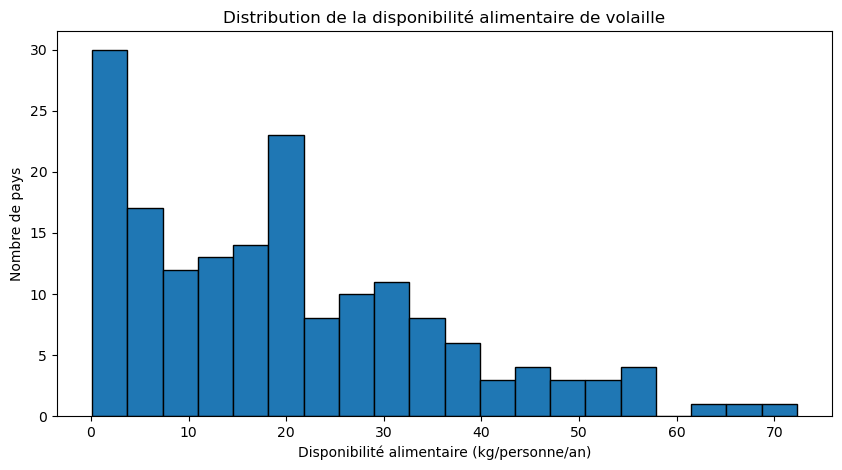

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    data_final["Disponibilité alimentaire en quantité (kg/personne/an)"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution de la disponibilité alimentaire de volaille")
plt.xlabel("Disponibilité alimentaire (kg/personne/an)")
plt.ylabel("Nombre de pays")

plt.show()

## 10. Analyse PESTEL et choix des variables complémentaires

Afin d'identifier les pays les plus pertinents pour une expansion internationale,
les variables utilisées dans l'analyse doivent être cohérentes avec les principaux
facteurs susceptibles d'influencer l'attractivité d'un marché.

L'analyse PESTEL est utilisée comme cadre de réflexion pour sélectionner des
indicateurs complémentaires aux données alimentaires de la FAO.

| Dimension PESTEL | Question métier | Indicateur envisagé |
|---|---|---|
| Politique | Le pays présente-t-il un environnement suffisamment stable pour développer une activité commerciale ? | Stabilité politique |
| Économique | Les consommateurs disposent-ils d'un pouvoir d'achat suffisant ? | PIB par habitant |
| Économique | L'économie du pays est-elle dynamique ? | Croissance du PIB |
| Social | Quelle est la taille potentielle du marché ? | Population |
| Social | La population est-elle fortement urbanisée ? | Taux d'urbanisation |
| Technologique | Les infrastructures facilitent-elles les échanges et la distribution ? | Indicateur logistique / infrastructures |
| Environnemental | Existe-t-il des contraintes environnementales susceptibles d'influencer le marché agricole et alimentaire ? | Indicateur environnemental pertinent |
| Légal | Le contexte réglementaire facilite-t-il les échanges commerciaux ? | Indicateur réglementaire ou commercial |

Les données déjà disponibles sur la volaille permettent également d'étudier
directement l'attractivité du marché :

- disponibilité alimentaire par habitant ;
- production locale ;
- importations ;
- exportations ;
- disponibilité intérieure ;
- taux de dépendance aux importations ;
- consommation totale estimée ;
- solde commercial.

L'objectif est de combiner des indicateurs de marché avec des variables issues
du cadre PESTEL afin d'obtenir une vision plus complète de l'attractivité des pays.

### 10.1 Sélection des variables PESTEL retenues

À partir du cadre PESTEL, plusieurs indicateurs peuvent être envisagés.
Cependant, seules les variables les plus pertinentes pour évaluer l'attractivité
commerciale d'un pays seront retenues dans l'analyse quantitative.

Les indicateurs complémentaires sélectionnés sont :

- **PIB par habitant** : permet d'approcher le niveau de richesse et le pouvoir
  d'achat potentiel des consommateurs ;
- **Croissance du PIB** : permet d'évaluer le dynamisme économique du pays ;
- **Stabilité politique** : permet d'apprécier le niveau de risque lié à
  l'environnement politique ;
- **Taux d'urbanisation** : permet d'évaluer la concentration de la population
  dans les zones urbaines, importantes pour la distribution alimentaire ;
- **Indicateur logistique** : permet d'apprécier la capacité du pays à faciliter
  le transport, l'importation et la distribution des marchandises.

La **population** est également un indicateur social important, mais elle est
déjà présente dans le jeu de données préparé précédemment.

Ces variables compléteront les indicateurs directement liés au marché de la
volaille afin de construire une analyse multicritère de l'attractivité des pays.

### 10.2 Identification des sources de données complémentaires

Les données FAO utilisées jusqu'à présent décrivent principalement le marché
de la volaille et la population. Elles ne permettent pas de mesurer directement
l'ensemble des dimensions retenues dans l'analyse PESTEL.

Des sources de données complémentaires sont donc nécessaires.

Les indicateurs recherchés sont :

- **PIB par habitant** ;
- **croissance du PIB** ;
- **stabilité politique** ;
- **taux d'urbanisation** ;
- **performance logistique**.

Pour garantir la fiabilité et la comparabilité des données entre les pays,
les sources institutionnelles internationales seront privilégiées,
notamment la **Banque mondiale**.

Dans la mesure du possible, les données correspondant à **l'année 2017**
seront utilisées afin de conserver une cohérence temporelle avec les données
FAO analysées précédemment.

### 10.3 Correspondance entre les dimensions PESTEL et les indicateurs retenus

Afin de traduire les dimensions du cadre PESTEL en variables quantitatives
exploitables dans l'analyse, les correspondances suivantes sont retenues :

| Dimension PESTEL | Indicateur retenu | Utilité pour l'analyse |
|---|---|---|
| Politique | Stabilité politique | Évaluer le niveau de risque politique du pays |
| Économique | PIB par habitant | Approcher le pouvoir d'achat potentiel |
| Économique | Croissance du PIB | Mesurer le dynamisme économique |
| Social | Population | Mesurer la taille potentielle du marché |
| Social | Taux d'urbanisation | Évaluer la concentration des consommateurs |
| Technologique | Performance logistique | Évaluer les capacités de transport et de distribution |

Les dimensions environnementale et légale restent pertinentes dans le cadre
PESTEL, mais ne sont pas retenues à ce stade dans l'analyse quantitative,
afin de privilégier des indicateurs comparables entre les pays et directement
liés à la problématique d'expansion internationale.

La population étant déjà disponible dans les données FAO préparées précédemment,
elle ne nécessite pas l'ajout d'une nouvelle source.

### 10.4 Récupération des données économiques — PIB par habitant

Le **PIB par habitant** est retenu comme indicateur économique permettant
d'approcher le niveau de richesse et le pouvoir d'achat potentiel des
consommateurs.

La source retenue est la **Banque mondiale**.

- **Indicateur :** PIB par habitant
- **Code Banque mondiale :** `NY.GDP.PCAP.CD`
- **Unité :** dollars US courants par habitant
- **Année de référence :** 2017
- **Dimension PESTEL :** Économique

L'objectif est d'intégrer cet indicateur au jeu de données sur la volaille afin
de compléter l'analyse de l'attractivité économique des différents pays.

In [36]:
# Récupération du PIB par habitant en 2017 - Banque mondiale

import requests
import pandas as pd

url_pib = (
    "https://api.worldbank.org/v2/country/all/"
    "indicator/NY.GDP.PCAP.CD"
    "?date=2017&format=json&per_page=400"
)

reponse_pib = requests.get(url_pib)

print("Statut de la requête :", reponse_pib.status_code)

Statut de la requête : 200


In [37]:
# Transformation des données PIB en DataFrame

donnees_pib = reponse_pib.json()[1]

pib_2017 = pd.DataFrame([
    {
        "Pays": ligne["country"]["value"],
        "Code_pays": ligne["countryiso3code"],
        "PIB_par_habitant": ligne["value"]
    }
    for ligne in donnees_pib
])

print("Dimensions du tableau PIB :", pib_2017.shape)

pib_2017.head(10)

Dimensions du tableau PIB : (265, 3)


,Pays,Code_pays,PIB_par_habitant
0,Africa Eastern and Southern,AFE,1529.923080
1,Africa Western and Central,AFW,1577.203497
2,Arab World,ARB,6105.921618
3,Caribbean small states,CSS,13708.752590
4,Central Europe and the Baltics,CEB,14339.848859
5,Early-demographic dividend,EAR,3457.917195
6,East Asia & Pacific,EAS,10612.793079
7,East Asia & Pacific (excluding high income),EAP,7241.983213
8,East Asia & Pacific (IDA & IBRD countries),TEA,7323.571124
9,Euro area,EMU,36691.210917


In [38]:
# Vérification du tableau PIB avant nettoyage

print("Nombre total de lignes :", len(pib_2017))

print("\nValeurs manquantes :")
print(pib_2017.isnull().sum())

print("\nNombre de PIB manquants :",
      pib_2017["PIB_par_habitant"].isna().sum())

print("\nExemples de lignes avec un PIB manquant :")
display(pib_2017[pib_2017["PIB_par_habitant"].isna()].head(10))

Nombre total de lignes : 265

Valeurs manquantes :
Pays                0
Code_pays           0
PIB_par_habitant    7
dtype: int64

Nombre de PIB manquants : 7

Exemples de lignes avec un PIB manquant :


,Pays,Code_pays,PIB_par_habitant
34,Not classified,,NaN
75,British Virgin Islands,VGB,NaN
109,Eritrea,ERI,NaN
123,Gibraltar,GIB,NaN
151,"Korea, Dem. People's Rep.",PRK,NaN
226,South Sudan,SSD,NaN
231,St. Martin (French part),MAF,NaN


### 10.8 Vérification de la correspondance entre les pays FAO et Banque mondiale

Les données de la Banque mondiale contiennent des pays mais également des
agrégats régionaux ou économiques.

L'analyse portant uniquement sur les pays présents dans le jeu de données
sur la volaille, une vérification de la correspondance des pays est réalisée
avant la fusion.

Cette étape permet notamment d'identifier les éventuelles différences de
nomenclature entre les données FAO et celles de la Banque mondiale.

In [39]:
# Vérification des DataFrames actuellement disponibles

import pandas as pd

for nom, objet in list(globals().items()):
    if isinstance(objet, pd.DataFrame):
        print(nom, ":", objet.shape)

__ : (10, 3)
df_dispo : (176600, 14)
df_population : (4411, 14)
_5 : (5, 14)
_6 : (5, 15)
population_2017 : (236, 15)
_16 : (5, 4)
_17 : (5, 3)
population_clean : (236, 3)
volaille : (2061, 14)
_20 : (5, 2)
unites_volaille : (5, 2)
_21 : (5, 7)
volaille_selection : (815, 14)
volaille_pivot : (172, 7)
_24 : (5, 9)
data_final : (172, 11)
_26 : (5, 8)
_27 : (10, 4)
_28 : (10, 4)
_29 : (10, 4)
_31 : (2, 4)
_32 : (2, 2)
_33 : (8, 9)
pib_2017 : (265, 3)
_37 : (10, 3)


In [40]:
# Vérification de la correspondance des noms de pays
# entre les données FAO et la Banque mondiale

pays_volaille = set(data_final["Zone"])
pays_pib = set(pib_2017["Pays"])

pays_non_trouves = sorted(pays_volaille - pays_pib)

print("Nombre de pays dans l'analyse volaille :", len(pays_volaille))
print("Nombre de pays sans correspondance directe :", len(pays_non_trouves))

print("\nPays sans correspondance directe :")
for pays in pays_non_trouves:
    print("-", pays)

Nombre de pays dans l'analyse volaille : 172
Nombre de pays sans correspondance directe : 121

Pays sans correspondance directe :
- Afrique du Sud
- Albanie
- Algérie
- Allemagne
- Antigua-et-Barbuda
- Arabie saoudite
- Argentine
- Arménie
- Australie
- Autriche
- Azerbaïdjan
- Bahamas
- Barbade
- Belgique
- Bolivie (État plurinational de)
- Bosnie-Herzégovine
- Brésil
- Bulgarie
- Bélarus
- Bénin
- Cambodge
- Cameroun
- Chili
- Chine - RAS de Hong-Kong
- Chine - RAS de Macao
- Chine, Taiwan Province de
- Chine, continentale
- Chypre
- Colombie
- Congo
- Croatie
- Côte d'Ivoire
- Danemark
- Dominique
- Espagne
- Estonie
- Fidji
- Finlande
- Fédération de Russie
- Gambie
- Grenade
- Grèce
- Guinée
- Guinée-Bissau
- Géorgie
- Haïti
- Hongrie
- Inde
- Indonésie
- Iran (République islamique d')
- Irlande
- Islande
- Israël
- Italie
- Jamaïque
- Japon
- Jordanie
- Kirghizistan
- Koweït
- Lettonie
- Liban
- Libéria
- Lituanie
- Macédoine du Nord
- Malaisie
- Malte
- Maroc
- Maurice
- Maurita

In [41]:
# Vérification des identifiants pays disponibles

print("Colonnes de data_final :")
print(data_final.columns.tolist())

print("\nExemple des codes FAO :")
display(data_final[["Code zone", "Zone"]].head(15))

print("\nExemple des codes Banque mondiale :")
display(pib_2017[["Code_pays", "Pays"]].head(15))

Colonnes de data_final :
['Code zone', 'Zone', 'Disponibilité alimentaire en quantité (kg/personne/an)', 'Disponibilité intérieure', 'Exportations - Quantité', 'Importations - Quantité', 'Production', 'Population', 'Taux_dependance_importations', 'Consommation_totale_tonnes', 'Solde_commercial']

Exemple des codes FAO :


,Code zone,Zone
0,1,Arménie
1,2,Afghanistan
2,3,Albanie
3,4,Algérie
4,7,Angola
5,8,Antigua-et-Barbuda
6,9,Argentine
7,10,Australie
8,11,Autriche
9,12,Bahamas



Exemple des codes Banque mondiale :


,Code_pays,Pays
0,AFE,Africa Eastern and Southern
1,AFW,Africa Western and Central
2,ARB,Arab World
3,CSS,Caribbean small states
4,CEB,Central Europe and the Baltics
5,EAR,Early-demographic dividend
6,EAS,East Asia & Pacific
7,EAP,East Asia & Pacific (excluding high income)
8,TEA,East Asia & Pacific (IDA & IBRD countries)
9,EMU,Euro area


In [42]:
# Vérification de quelques pays dans les données Banque mondiale

pays_test = [
    "Afghanistan",
    "Albania",
    "Algeria",
    "Armenia",
    "Australia",
    "Austria",
    "Brazil",
    "Germany",
    "South Africa"
]

pib_2017[
    pib_2017["Pays"].isin(pays_test)
][["Pays", "Code_pays", "PIB_par_habitant"]]

,Pays,Code_pays,PIB_par_habitant
48,Afghanistan,AFG,525.469771
49,Albania,ALB,5006.360130
50,Algeria,DZA,4554.667540
56,Armenia,ARM,3869.053739
58,Australia,AUS,54117.547719
59,Austria,AUT,47163.742578
74,Brazil,BRA,10080.509282
121,Germany,DEU,45553.934150
225,South Africa,ZAF,6618.335083


In [43]:
# Vérification de la disponibilité de la bibliothèque pycountry

try:
    import pycountry
    print("pycountry est disponible.")
except ImportError:
    print("pycountry n'est pas installé.")

pycountry est disponible.


In [44]:
# Installation de la bibliothèque pycountry

%pip install pycountry

Note: you may need to restart the kernel to use updated packages.


In [45]:
# Vérification après redémarrage du kernel

import pycountry

print("pycountry est maintenant disponible.")
print("Version :", pycountry.__version__)

pycountry est maintenant disponible.
Version : 26.2.16


In [46]:
# Test de reconnaissance des noms de pays FAO par pycountry

pays_test_fao = [
    "Afghanistan",
    "Albanie",
    "Algérie",
    "Arménie",
    "Australie",
    "Autriche",
    "Brésil",
    "Allemagne",
    "Afrique du Sud"
]

for pays in pays_test_fao:
    try:
        resultat = pycountry.countries.lookup(pays)
        print(pays, "→", resultat.name, "→", resultat.alpha_3)
    except LookupError:
        print(pays, "→ NON RECONNU")

Afghanistan → Afghanistan → AFG
Albanie → NON RECONNU
Algérie → NON RECONNU
Arménie → NON RECONNU
Australie → NON RECONNU
Autriche → NON RECONNU
Brésil → NON RECONNU
Allemagne → NON RECONNU
Afrique du Sud → NON RECONNU


In [47]:
# Vérification de quelques codes FAO avec pycountry

codes_fao_test = [1, 2, 3, 4, 7, 9, 10, 11, 21]

for code in codes_fao_test:
    try:
        resultat = pycountry.countries.get(numeric=str(code).zfill(3))
        
        if resultat:
            print(code, "→", resultat.name, "→", resultat.alpha_3)
        else:
            print(code, "→ NON RECONNU")
            
    except Exception:
        print(code, "→ NON RECONNU")

1 → NON RECONNU
2 → NON RECONNU
3 → NON RECONNU
4 → Afghanistan → AFG
7 → NON RECONNU
9 → NON RECONNU
10 → Antarctica → ATA
11 → NON RECONNU
21 → NON RECONNU


In [48]:
# Vérification de la disponibilité de country_converter

try:
    import country_converter as coco
    print("country_converter est disponible.")
except ImportError:
    print("country_converter n'est pas installé.")

country_converter est disponible.


In [49]:
# Installation de la bibliothèque country_converter

%pip install country_converter

Note: you may need to restart the kernel to use updated packages.


In [50]:
# Vérification après installation de country_converter

import country_converter as coco

print("country_converter est maintenant disponible.")

country_converter est maintenant disponible.


In [51]:
# Test de conversion des noms FAO vers les codes ISO-3

pays_test = [
    "Afghanistan",
    "Albanie",
    "Algérie",
    "Arménie",
    "Australie",
    "Autriche",
    "Brésil",
    "Allemagne",
    "Afrique du Sud"
]

for pays in pays_test:
    code_iso3 = coco.convert(names=pays, to="ISO3")
    print(pays, "→", code_iso3)

Afghanistan

Albanie not found in regex


 → AFG
Albanie → not found


Algérie not found in regex
Arménie not found in regex


Algérie → not found
Arménie → not found


Australie not found in regex
Autriche not found in regex


Australie → not found
Autriche → not found


Brésil not found in regex
Allemagne not found in regex


Brésil → not found
Allemagne → not found


Afrique du Sud not found in regex


Afrique du Sud → not found


In [52]:
# Test d'une table de correspondance FAO → ISO3

correspondance_test = {
    "Afghanistan": "AFG",
    "Albanie": "ALB",
    "Algérie": "DZA",
    "Arménie": "ARM",
    "Australie": "AUS",
    "Autriche": "AUT",
    "Brésil": "BRA",
    "Allemagne": "DEU",
    "Afrique du Sud": "ZAF"
}

test_iso = data_final.loc[
    data_final["Zone"].isin(correspondance_test.keys()),
    ["Zone"]
].copy()

test_iso["Code_ISO3"] = test_iso["Zone"].map(correspondance_test)

display(test_iso)

,Zone,Code_ISO3
0,Arménie,ARM
1,Afghanistan,AFG
2,Albanie,ALB
3,Algérie,DZA
7,Australie,AUS
8,Autriche,AUT
14,Brésil,BRA
50,Allemagne,DEU
137,Afrique du Sud,ZAF


In [53]:
# Vérification des classifications disponibles dans country_converter

cc = coco.CountryConverter()

print(cc.valid_class)

['APEC', 'BASIC', 'BRIC', 'CC41', 'CIS', 'Cecilia2050', 'CoE', 'Continent_7', 'DACcode', 'EEA', 'EU', 'EU12', 'EU15', 'EU25', 'EU27', 'EU27_2007', 'EU28', 'EURO', 'EXIO1', 'EXIO1_3L', 'EXIO2', 'EXIO2_3L', 'EXIO3', 'EXIO3_3L', 'Eora', 'FAOcode', 'FIFA', 'G20', 'G7', 'GBDcode', 'GEOnumeric', 'GWcode', 'IEA', 'IMAGE', 'IOC', 'ISO2', 'ISO3', 'ISOnumeric', 'MESSAGE', 'OECD', 'REMIND', 'Schengen', 'UN', 'UNcode', 'UNmember', 'UNregion', 'WIOD', 'ccTLD', 'continent', 'name_official', 'name_short', 'obsolete', 'regex']


In [54]:
# Test de conversion des codes FAO vers ISO3

codes_fao_test = [1, 2, 3, 4, 7, 10, 11, 21]

for code in codes_fao_test:
    code_iso3 = coco.convert(
        names=str(code),
        src="FAOcode",
        to="ISO3"
    )
    print(code, "→", code_iso3)

1 → ARM
2 → AFG
3 → ALB
4 → DZA
7 → AGO
10 → AUS
11 → AUT
21 → BRA


In [55]:
# Ajout des codes ISO3 à partir des codes FAO

data_pestel = data_final.copy()

data_pestel["Code_ISO3"] = coco.convert(
    names=data_pestel["Code zone"].astype(str).tolist(),
    src="FAOcode",
    to="ISO3"
)

print("Dimensions :", data_pestel.shape)

display(
    data_pestel[
        ["Code zone", "Zone", "Code_ISO3"]
    ].head(15)
)

41 not found in FAOcode
276 not found in FAOcode


Dimensions : (172, 12)


,Code zone,Zone,Code_ISO3
0,1,Arménie,ARM
1,2,Afghanistan,AFG
2,3,Albanie,ALB
3,4,Algérie,DZA
4,7,Angola,AGO
5,8,Antigua-et-Barbuda,ATG
6,9,Argentine,ARG
7,10,Australie,AUS
8,11,Autriche,AUT
9,12,Bahamas,BHS


In [56]:
# Identification des deux codes FAO non reconnus

pays_non_reconnus = data_pestel[
    data_pestel["Code zone"].isin([41, 276])
][["Code zone", "Zone", "Code_ISO3"]]

display(pays_non_reconnus)

,Code zone,Zone,Code_ISO3
26,41,"Chine, continentale",not found
171,276,Soudan,not found


In [57]:
# Correction manuelle des deux codes FAO non reconnus

corrections_iso3 = {
    41: "CHN",   # Chine, continentale
    276: "SDN"   # Soudan
}

data_pestel["Code_ISO3"] = data_pestel.apply(
    lambda ligne: corrections_iso3.get(
        ligne["Code zone"],
        ligne["Code_ISO3"]
    ),
    axis=1
)

display(
    data_pestel[
        data_pestel["Code zone"].isin([41, 276])
    ][["Code zone", "Zone", "Code_ISO3"]]
)

,Code zone,Zone,Code_ISO3
26,41,"Chine, continentale",CHN
171,276,Soudan,SDN


In [58]:
# Contrôle final des codes ISO3 avant fusion

nb_not_found = (data_pestel["Code_ISO3"] == "not found").sum()
nb_manquants = data_pestel["Code_ISO3"].isna().sum()
nb_codes_uniques = data_pestel["Code_ISO3"].nunique()

print("Nombre de lignes :", len(data_pestel))
print("Codes ISO3 'not found' :", nb_not_found)
print("Codes ISO3 manquants :", nb_manquants)
print("Nombre de codes ISO3 uniques :", nb_codes_uniques)

Nombre de lignes : 172
Codes ISO3 'not found' : 0
Codes ISO3 manquants : 0
Nombre de codes ISO3 uniques : 172


In [59]:
# Fusion du jeu de données avec le PIB par habitant 2017

data_pestel = data_pestel.merge(
    pib_2017[["Code_pays", "PIB_par_habitant"]],
    left_on="Code_ISO3",
    right_on="Code_pays",
    how="left"
)

print("Dimensions après fusion :", data_pestel.shape)

display(
    data_pestel[
        ["Zone", "Code_ISO3", "PIB_par_habitant"]
    ].head(15)
)

Dimensions après fusion : (172, 14)


,Zone,Code_ISO3,PIB_par_habitant
0,Arménie,ARM,3869.053739
1,Afghanistan,AFG,525.469771
2,Albanie,ALB,5006.360130
3,Algérie,DZA,4554.667540
4,Angola,AGO,2832.149980
5,Antigua-et-Barbuda,ATG,16965.728827
6,Argentine,ARG,14532.500931
7,Australie,AUS,54117.547719
8,Autriche,AUT,47163.742578
9,Bahamas,BHS,31875.488175


In [60]:
# Contrôle des valeurs manquantes du PIB après fusion

nb_pib_manquants = data_pestel["PIB_par_habitant"].isna().sum()

print("Nombre total de pays :", len(data_pestel))
print("Nombre de PIB manquants :", nb_pib_manquants)

if nb_pib_manquants > 0:
    print("\nPays concernés :")
    display(
        data_pestel.loc[
            data_pestel["PIB_par_habitant"].isna(),
            ["Zone", "Code_ISO3", "PIB_par_habitant"]
        ]
    )
else:
    print("\nTous les pays disposent d'un PIB par habitant pour 2017.")

Nombre total de pays : 172
Nombre de PIB manquants : 2

Pays concernés :


,Zone,Code_ISO3,PIB_par_habitant
80,République populaire démocratique de Corée,PRK,NaN
145,"Chine, Taiwan Province de",TWN,NaN


### 10.9 Contrôle des valeurs manquantes du PIB par habitant

Après la fusion avec les données de la Banque mondiale, le jeu de données conserve **172 pays**.

Deux pays ne disposent pas d'une valeur de PIB par habitant pour l'année 2017 dans les données récupérées :

- République populaire démocratique de Corée (PRK) ;
- Chine, Taiwan Province de (TWN).

Ces deux valeurs représentent environ **1,16 %** des observations.

Aucune imputation n'est réalisée à ce stade afin de ne pas introduire de valeurs économiques artificielles susceptibles de biaiser l'analyse multicritère. Ces valeurs manquantes seront prises en compte lors de la préparation finale des variables utilisées pour la segmentation des pays.

### 10.10 Récupération des données économiques — Croissance du PIB

La **croissance du PIB** est retenue comme second indicateur de la dimension économique du cadre PESTEL.

Alors que le PIB par habitant permet d'approcher le niveau de richesse et le pouvoir d'achat potentiel des consommateurs, la croissance du PIB permet d'évaluer le **dynamisme économique du pays**.

La source retenue est la **Banque mondiale**.

- **Indicateur :** croissance annuelle du PIB
- **Code Banque mondiale :** `NY.GDP.MKTP.KD.ZG`
- **Unité :** pourcentage annuel (%)
- **Année de référence :** 2017
- **Dimension PESTEL :** Économique

L'objectif est d'intégrer cet indicateur au jeu de données afin de compléter l'évaluation de l'attractivité économique des différents pays.

In [61]:
# Récupération de la croissance du PIB en 2017 - Banque mondiale

url_croissance = (
    "https://api.worldbank.org/v2/country/all/"
    "indicator/NY.GDP.MKTP.KD.ZG"
    "?date=2017&format=json&per_page=400"
)

response_croissance = requests.get(url_croissance)

print("Statut de la requête :", response_croissance.status_code)

Statut de la requête : 200


In [62]:
# Création du DataFrame de croissance du PIB en 2017

data_croissance = response_croissance.json()[1]

croissance_2017 = pd.DataFrame([
    {
        "Pays": ligne["country"]["value"],
        "Code_ISO3": ligne["countryiso3code"],
        "Croissance_PIB": ligne["value"]
    }
    for ligne in data_croissance
])

print("Dimensions du tableau croissance :", croissance_2017.shape)

display(croissance_2017.head(10))

Dimensions du tableau croissance : (265, 3)


,Pays,Code_ISO3,Croissance_PIB
0,Africa Eastern and Southern,AFE,2.678863
1,Africa Western and Central,AFW,2.302761
2,Arab World,ARB,1.331270
3,Caribbean small states,CSS,-0.750656
4,Central Europe and the Baltics,CEB,5.107131
5,Early-demographic dividend,EAR,4.490007
6,East Asia & Pacific,EAS,5.036670
7,East Asia & Pacific (excluding high income),EAP,6.666665
8,East Asia & Pacific (IDA & IBRD countries),TEA,6.666384
9,Euro area,EMU,2.623157


In [63]:
# Vérification des valeurs manquantes - Croissance du PIB 2017

print("Nombre total de lignes :", len(croissance_2017))

print("\nValeurs manquantes :")
print(croissance_2017.isna().sum())

nb_manquants = croissance_2017["Croissance_PIB"].isna().sum()
print("\nNombre de croissances du PIB manquantes :", nb_manquants)

print("\nExemples de lignes avec une croissance du PIB manquante :")
display(
    croissance_2017[croissance_2017["Croissance_PIB"].isna()]
)

Nombre total de lignes : 265

Valeurs manquantes :
Pays              0
Code_ISO3         0
Croissance_PIB    8
dtype: int64

Nombre de croissances du PIB manquantes : 8

Exemples de lignes avec une croissance du PIB manquante :


,Pays,Code_ISO3,Croissance_PIB
34,Not classified,,NaN
75,British Virgin Islands,VGB,NaN
109,Eritrea,ERI,NaN
123,Gibraltar,GIB,NaN
151,"Korea, Dem. People's Rep.",PRK,NaN
162,Liechtenstein,LIE,NaN
188,New Caledonia,NCL,NaN
226,South Sudan,SSD,NaN


In [64]:
# Fusion de la croissance du PIB avec le jeu de données PESTEL

data_pestel = data_pestel.merge(
    croissance_2017[["Code_ISO3", "Croissance_PIB"]],
    on="Code_ISO3",
    how="left"
)

print("Dimensions après ajout de la croissance du PIB :", data_pestel.shape)

display(
    data_pestel[
        ["Zone", "Code_ISO3", "PIB_par_habitant", "Croissance_PIB"]
    ].head(15)
)

Dimensions après ajout de la croissance du PIB : (172, 15)


,Zone,Code_ISO3,PIB_par_habitant,Croissance_PIB
0,Arménie,ARM,3869.053739,7.500000
1,Afghanistan,AFG,525.469771,2.647003
2,Albanie,ALB,5006.360130,3.283176
3,Algérie,DZA,4554.667540,1.500000
4,Angola,AGO,2832.149980,-0.164689
5,Antigua-et-Barbuda,ATG,16965.728827,2.712727
6,Argentine,ARG,14532.500931,2.818503
7,Australie,AUS,54117.547719,2.293310
8,Autriche,AUT,47163.742578,2.272250
9,Bahamas,BHS,31875.488175,3.371399


In [65]:
# Vérification des valeurs manquantes après fusion - Croissance du PIB

nb_croissance_manquante = data_pestel["Croissance_PIB"].isna().sum()

print("Nombre total de pays :", len(data_pestel))
print("Nombre de croissances du PIB manquantes :", nb_croissance_manquante)

print("\nPays concernés :")

display(
    data_pestel.loc[
        data_pestel["Croissance_PIB"].isna(),
        ["Zone", "Code_ISO3", "Croissance_PIB"]
    ]
)

Nombre total de pays : 172
Nombre de croissances du PIB manquantes : 3

Pays concernés :


,Zone,Code_ISO3,Croissance_PIB
80,République populaire démocratique de Corée,PRK,NaN
106,Nouvelle-Calédonie,NCL,NaN
145,"Chine, Taiwan Province de",TWN,NaN


### 10.11 Contrôle de la qualité des données — Croissance du PIB

Après intégration de la croissance du PIB de 2017, le jeu de données contient toujours **172 pays**.

Parmi eux, **3 pays présentent une valeur manquante** pour cet indicateur :
- République populaire démocratique de Corée ;
- Nouvelle-Calédonie ;
- Chine, Taiwan Province de.

Ces valeurs manquantes sont conservées à ce stade afin de ne pas supprimer prématurément des pays de l'analyse. Leur traitement sera réalisé ultérieurement lors de la préparation des données pour l'analyse multivariée.

L'intégration de la croissance du PIB permet désormais de compléter la dimension **économique** du cadre PESTEL avec deux indicateurs : le **PIB par habitant** et la **croissance du PIB**.

## 10.12 Récupération des données politiques — Stabilité politique

La **stabilité politique** est retenue comme indicateur de la dimension politique du cadre PESTEL.

Cet indicateur permet d'évaluer le niveau de risque lié à l'environnement politique d'un pays. Un environnement politiquement stable peut favoriser le développement d'une activité commerciale et réduire certains risques liés à une expansion internationale.

La source retenue est la **Banque mondiale**, à travers les *Worldwide Governance Indicators (WGI)*.

- **Indicateur :** stabilité politique et absence de violence/terrorisme
- **Code Banque mondiale :** `PV.EST`
- **Unité :** estimation de l'indicateur de gouvernance
- **Année de référence :** 2017
- **Dimension PESTEL :** Politique

Une valeur plus élevée de l'indicateur traduit globalement une **meilleure stabilité politique**, tandis qu'une valeur plus faible traduit un environnement politique plus fragile.

L'objectif est d'intégrer cet indicateur au jeu de données afin de prendre en compte le **risque politique** dans l'évaluation de l'attractivité des pays.

In [66]:
# Récupération de la stabilité politique en 2017 - Banque mondiale

url_stabilite = (
    "https://api.worldbank.org/v2/country/all/"
    "indicator/PV.EST"
    "?date=2017&format=json&per_page=400"
)

response_stabilite = requests.get(url_stabilite)

print("Statut de la requête :", response_stabilite.status_code)

Statut de la requête : 200


In [67]:
# Vérification du contenu réellement renvoyé par l'API

print("Statut :", response_stabilite.status_code)

contenu_stabilite = response_stabilite.json()

print("Type :", type(contenu_stabilite))
print("Nombre d'éléments :", len(contenu_stabilite))

print("\nContenu renvoyé par l'API :")
print(contenu_stabilite)

Statut : 200
Type : <class 'list'>
Nombre d'éléments : 1

Contenu renvoyé par l'API :
[{'message': [{'id': '175', 'key': 'Invalid format', 'value': 'The indicator was not found. It may have been deleted or archived.'}]}]


### 10.13 Adaptation de la source pour l'indicateur de stabilité politique

L'indicateur `PV.EST` est bien référencé dans les **Worldwide Governance Indicators (WGI)**
de la Banque mondiale.

Cependant, la requête effectuée via l'API standard utilisée pour les indicateurs économiques
ne renvoie pas directement les observations de cet indicateur.

La récupération des données de stabilité politique sera donc réalisée à partir de la base
**Worldwide Governance Indicators (WGI)** de la Banque mondiale, afin de conserver une source
institutionnelle fiable et comparable entre les pays.

In [68]:
# Lecture des données WGI - Stabilité politique

import pandas as pd

fichier_wgi = "wgidataset_with_sourcedata-2025.xlsx"

wgi_pv = pd.read_excel(fichier_wgi, sheet_name="pv")

print("Dimensions :", wgi_pv.shape)
print("\nColonnes disponibles :")
print(wgi_pv.columns.tolist())

Dimensions : (5429, 51)

Colonnes disponibles :
['ID variable (economy code/ gov. dimension/ year)', 'Economy (name)', 'Economy (code)', 'Region', 'Income classification', 'Year', 'Governance dimension', 'Number of sources', 'Governance estimate (approx. -2.5 to +2.5)', 'Standard error (estimate)', 'Lower threshold (90% conf. int. estimate)', 'Upper threshold (90% conf. int. estimate)', 'Governance score (0-100)', 'Standard error (gov. score)', 'Lower threshold (90% conf. int. score)', 'Upper threshold (90% conf. int. score)', 'ADB mean', 'AFR mean', 'ARB mean', 'ASB mean', 'ASD mean', 'BPS mean', 'BTI mean', 'CCR mean', 'EBR mean', 'EIU mean', 'EQI mean', 'EUB mean', 'FRH mean', 'GCB mean', 'GCS mean', 'GII mean', 'GWP mean', 'HER mean', 'HRM mean', 'HUM mean', 'IFD mean', 'IJT mean', 'IRP mean', 'LBO mean', 'MSI mean', 'OBI mean', 'PIA mean', 'PRS mean', 'RSF mean', 'VAB mean', 'VDM mean', 'WBS mean', 'WCY mean', 'WJP mean', 'WMO mean']


In [69]:
# Sélection de la stabilité politique pour l'année 2017

stabilite_2017 = wgi_pv[
    wgi_pv["Year"] == 2017
][[
    "Economy (name)",
    "Economy (code)",
    "Governance estimate (approx. -2.5 to +2.5)"
]].copy()

stabilite_2017.columns = [
    "Pays",
    "Code_ISO3",
    "Stabilite_politique"
]

print("Dimensions :", stabilite_2017.shape)

display(stabilite_2017.head(10))

Dimensions : (212, 3)


,Pays,Code_ISO3,Stabilite_politique
3713,Aruba,ABW,1.206665
3714,Andorra,ADO,1.325091
3715,Afghanistan,AFG,-2.613931
3716,Angola,AGO,-0.537214
3717,Anguilla,AIA,1.221763
3718,Albania,ALB,0.163830
3719,Netherlands Antilles (former),ANT,0.711973
3720,United Arab Emirates,ARE,0.719287
3721,Argentina,ARG,0.239407
3722,Armenia,ARM,-0.301588


In [70]:
# Contrôle qualité de la stabilité politique 2017

print("Nombre total de lignes :", len(stabilite_2017))

print("\nValeurs manquantes :")
print(stabilite_2017.isna().sum())

print("\nNombre de codes ISO3 uniques :",
      stabilite_2017["Code_ISO3"].nunique())

print("Nombre de codes ISO3 dupliqués :",
      stabilite_2017["Code_ISO3"].duplicated().sum())

Nombre total de lignes : 212

Valeurs manquantes :
Pays                   0
Code_ISO3              0
Stabilite_politique    0
dtype: int64

Nombre de codes ISO3 uniques : 212
Nombre de codes ISO3 dupliqués : 0


In [71]:
# Ajout de la stabilité politique au jeu de données PESTEL

data_pestel = data_pestel.merge(
    stabilite_2017[["Code_ISO3", "Stabilite_politique"]],
    on="Code_ISO3",
    how="left"
)

print("Dimensions après ajout de la stabilité politique :", data_pestel.shape)

display(
    data_pestel[
        ["Zone", "Code_ISO3", "PIB_par_habitant",
         "Croissance_PIB", "Stabilite_politique"]
    ].head(15)
)

Dimensions après ajout de la stabilité politique : (172, 16)


,Zone,Code_ISO3,PIB_par_habitant,Croissance_PIB,Stabilite_politique
0,Arménie,ARM,3869.053739,7.500000,-0.301588
1,Afghanistan,AFG,525.469771,2.647003,-2.613931
2,Albanie,ALB,5006.360130,3.283176,0.163830
3,Algérie,DZA,4554.667540,1.500000,-0.929505
4,Angola,AGO,2832.149980,-0.164689,-0.537214
5,Antigua-et-Barbuda,ATG,16965.728827,2.712727,0.614623
6,Argentine,ARG,14532.500931,2.818503,0.239407
7,Australie,AUS,54117.547719,2.293310,0.783148
8,Autriche,AUT,47163.742578,2.272250,0.926696
9,Bahamas,BHS,31875.488175,3.371399,0.818667


In [72]:
# Contrôle des valeurs manquantes après fusion

nb_manquants_stabilite = data_pestel["Stabilite_politique"].isna().sum()

print("Nombre total de pays :", len(data_pestel))
print("Nombre de stabilités politiques manquantes :", nb_manquants_stabilite)

print("\nPays concernés :")

display(
    data_pestel.loc[
        data_pestel["Stabilite_politique"].isna(),
        ["Zone", "Code_ISO3", "Stabilite_politique"]
    ]
)

Nombre total de pays : 172
Nombre de stabilités politiques manquantes : 2

Pays concernés :


,Zone,Code_ISO3,Stabilite_politique
45,Polynésie française,PYF,NaN
106,Nouvelle-Calédonie,NCL,NaN


### 10.14 Contrôle de la qualité des données — Stabilité politique

Après intégration de l'indicateur de stabilité politique pour l'année 2017, le jeu de données contient toujours **172 pays et territoires**.

Parmi eux, **2 présentent une valeur manquante** pour cet indicateur :

- Polynésie française ;
- Nouvelle-Calédonie.

Ces valeurs manquantes sont conservées à ce stade afin de ne pas supprimer prématurément des observations de l'analyse. Leur traitement sera réalisé ultérieurement lors de la préparation des données pour l'analyse multivariée.

L'intégration de cet indicateur permet de compléter la **dimension politique du cadre PESTEL** et de prendre en compte le niveau de risque politique dans l'évaluation de l'attractivité des pays.

### 10.15 Récupération des données sociales — Taux d'urbanisation

Le **taux d'urbanisation** est retenu comme second indicateur de la dimension sociale du cadre PESTEL.

Alors que la population permet d'évaluer la taille potentielle du marché, le taux d'urbanisation permet d'apprécier la **concentration des consommateurs dans les zones urbaines**, ce qui peut faciliter la distribution et l'accès au marché.

La source retenue est la **Banque mondiale**.

- **Indicateur :** population urbaine (% de la population totale)
- **Code Banque mondiale :** `SP.URB.TOTL.IN.ZS`
- **Unité :** pourcentage de la population totale (%)
- **Année de référence :** 2017
- **Dimension PESTEL :** Sociale

L'objectif est d'intégrer cet indicateur au jeu de données afin de compléter l'évaluation du potentiel de marché des différents pays.

In [73]:
# Récupération du taux d'urbanisation en 2017 - Banque mondiale

url_urbanisation = (
    "https://api.worldbank.org/v2/country/all/"
    "indicator/SP.URB.TOTL.IN.ZS"
    "?date=2017&format=json&per_page=400"
)

response_urbanisation = requests.get(url_urbanisation)

print("Statut de la requête :", response_urbanisation.status_code)

Statut de la requête : 200


In [74]:
# Création du DataFrame du taux d'urbanisation en 2017

data_urbanisation = response_urbanisation.json()[1]

urbanisation_2017 = pd.DataFrame([
    {
        "Pays": ligne["country"]["value"],
        "Code_ISO3": ligne["countryiso3code"],
        "Taux_urbanisation": ligne["value"]
    }
    for ligne in data_urbanisation
])

print("Dimensions du tableau urbanisation :", urbanisation_2017.shape)

display(urbanisation_2017.head(10))

Dimensions du tableau urbanisation : (265, 3)


,Pays,Code_ISO3,Taux_urbanisation
0,Africa Eastern and Southern,AFE,35.282987
1,Africa Western and Central,AFW,48.761009
2,Arab World,ARB,58.680894
3,Caribbean small states,CSS,50.178296
4,Central Europe and the Baltics,CEB,61.871576
5,Early-demographic dividend,EAR,45.124936
6,East Asia & Pacific,EAS,59.803708
7,East Asia & Pacific (excluding high income),EAP,56.465464
8,East Asia & Pacific (IDA & IBRD countries),TEA,56.398837
9,Euro area,EMU,76.414081


In [75]:
# Contrôle qualité du taux d'urbanisation 2017

print("Valeurs manquantes :")
print(urbanisation_2017.isna().sum())

print(
    "\nNombre de taux d'urbanisation manquants :",
    urbanisation_2017["Taux_urbanisation"].isna().sum()
)

print("\nExemples de lignes avec un taux d'urbanisation manquant :")

display(
    urbanisation_2017[
        urbanisation_2017["Taux_urbanisation"].isna()
    ].head(10)
)

Valeurs manquantes :
Pays                 0
Code_ISO3            0
Taux_urbanisation    1
dtype: int64

Nombre de taux d'urbanisation manquants : 1

Exemples de lignes avec un taux d'urbanisation manquant :


,Pays,Code_ISO3,Taux_urbanisation
34,Not classified,,NaN


In [76]:
# Ajout du taux d'urbanisation au jeu de données PESTEL

data_pestel = data_pestel.merge(
    urbanisation_2017[["Code_ISO3", "Taux_urbanisation"]],
    on="Code_ISO3",
    how="left"
)

print(
    "Dimensions après ajout du taux d'urbanisation :",
    data_pestel.shape
)

display(
    data_pestel[
        [
            "Zone",
            "Code_ISO3",
            "PIB_par_habitant",
            "Croissance_PIB",
            "Stabilite_politique",
            "Taux_urbanisation"
        ]
    ].head(15)
)

Dimensions après ajout du taux d'urbanisation : (172, 17)


,Zone,Code_ISO3,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation
0,Arménie,ARM,3869.053739,7.500000,-0.301588,64.712495
1,Afghanistan,AFG,525.469771,2.647003,-2.613931,24.835282
2,Albanie,ALB,5006.360130,3.283176,0.163830,55.980276
3,Algérie,DZA,4554.667540,1.500000,-0.929505,71.322791
4,Angola,AGO,2832.149980,-0.164689,-0.537214,65.085053
5,Antigua-et-Barbuda,ATG,16965.728827,2.712727,0.614623,24.850026
6,Argentine,ARG,14532.500931,2.818503,0.239407,91.677603
7,Australie,AUS,54117.547719,2.293310,0.783148,87.128093
8,Autriche,AUT,47163.742578,2.272250,0.926696,67.905120
9,Bahamas,BHS,31875.488175,3.371399,0.818667,82.081402


In [77]:
# Contrôle des valeurs manquantes après ajout du taux d'urbanisation

nb_manquants_urbanisation = data_pestel["Taux_urbanisation"].isna().sum()

print("Nombre total de pays :", len(data_pestel))
print("Nombre de taux d'urbanisation manquants :", nb_manquants_urbanisation)

print("\nPays concernés :")

display(
    data_pestel.loc[
        data_pestel["Taux_urbanisation"].isna(),
        ["Zone", "Code_ISO3", "Taux_urbanisation"]
    ]
)

Nombre total de pays : 172
Nombre de taux d'urbanisation manquants : 1

Pays concernés :


,Zone,Code_ISO3,Taux_urbanisation
145,"Chine, Taiwan Province de",TWN,NaN


## 10.16 Contrôle de la qualité des données — Taux d'urbanisation

Après intégration du taux d'urbanisation pour l'année 2017, le jeu de données contient toujours **172 pays et territoires**.

Parmi eux, **1 présente une valeur manquante** pour cet indicateur :

- Chine, Taiwan Province de.

Cette valeur manquante est conservée à ce stade afin de ne pas supprimer prématurément une observation de l'analyse. Son traitement sera réalisé ultérieurement lors de la préparation des données pour l'analyse multivariée.

L'intégration du taux d'urbanisation permet de compléter la **dimension sociale du cadre PESTEL**, en complément de la population, en apportant une information sur la concentration de la population dans les zones urbaines.

## 10.17 Récupération des données technologiques — Utilisation d'Internet

L'utilisation d'Internet est retenue comme indicateur de la **dimension technologique** du cadre PESTEL.

Cet indicateur permet d'apprécier le niveau de **digitalisation de la population** et l'accessibilité potentielle des consommateurs aux services numériques. Un taux d'utilisation d'Internet élevé peut notamment favoriser le commerce en ligne, la communication digitale et le développement de nouveaux canaux de distribution.

La source retenue est la **Banque mondiale**.

- **Indicateur :** individus utilisant Internet (% de la population)
- **Code Banque mondiale :** `IT.NET.USER.ZS`
- **Unité :** pourcentage de la population (%)
- **Année de référence :** 2017
- **Dimension PESTEL :** Technologique

L'objectif est d'intégrer cet indicateur au jeu de données afin de prendre en compte le niveau de développement numérique des différents pays dans l'évaluation de leur attractivité.

In [78]:
# Récupération de l'utilisation d'Internet en 2017 - Banque mondiale

url_internet = (
    "https://api.worldbank.org/v2/country/all/"
    "indicator/IT.NET.USER.ZS"
    "?date=2017&format=json&per_page=400"
)

response_internet = requests.get(url_internet)

print("Statut de la requête :", response_internet.status_code)

Statut de la requête : 200


In [79]:
# Création du DataFrame de l'utilisation d'Internet en 2017

data_internet = response_internet.json()[1]

internet_2017 = pd.DataFrame([
    {
        "Pays": ligne["country"]["value"],
        "Code_ISO3": ligne["countryiso3code"],
        "Utilisation_Internet": ligne["value"]
    }
    for ligne in data_internet
])

print("Dimensions du tableau Internet :", internet_2017.shape)

display(internet_2017.head(10))

Dimensions du tableau Internet : (265, 3)


,Pays,Code_ISO3,Utilisation_Internet
0,Africa Eastern and Southern,AFE,17.3
1,Africa Western and Central,AFW,23.8
2,Arab World,ARB,NaN
3,Caribbean small states,CSS,NaN
4,Central Europe and the Baltics,CEB,NaN
5,Early-demographic dividend,EAR,NaN
6,East Asia & Pacific,EAS,57.8
7,East Asia & Pacific (excluding high income),EAP,53.9
8,East Asia & Pacific (IDA & IBRD countries),TEA,54.6
9,Euro area,EMU,NaN


In [80]:
# Contrôle qualité des données d'utilisation d'Internet en 2017

print("Valeurs manquantes :")
print(internet_2017.isna().sum())

print(
    "\nNombre de valeurs Internet manquantes :",
    internet_2017["Utilisation_Internet"].isna().sum()
)

print("\nExemples de lignes avec une valeur Internet manquante :")

display(
    internet_2017[
        internet_2017["Utilisation_Internet"].isna()
    ].head(15)
)

Valeurs manquantes :
Pays                     0
Code_ISO3                0
Utilisation_Internet    33
dtype: int64

Nombre de valeurs Internet manquantes : 33

Exemples de lignes avec une valeur Internet manquante :


,Pays,Code_ISO3,Utilisation_Internet
2,Arab World,ARB,NaN
3,Caribbean small states,CSS,NaN
4,Central Europe and the Baltics,CEB,NaN
5,Early-demographic dividend,EAR,NaN
9,Euro area,EMU,NaN
13,European Union,EUU,NaN
14,Heavily indebted poor countries (HIPC),HPC,NaN
21,Late-demographic dividend,LTE,NaN
26,Low & middle income,LMY,NaN
32,Middle income,MIC,NaN


In [81]:
# Ajout de l'utilisation d'Internet au jeu de données PESTEL

data_pestel = data_pestel.merge(
    internet_2017[["Code_ISO3", "Utilisation_Internet"]],
    on="Code_ISO3",
    how="left"
)

print(
    "Dimensions après ajout de l'utilisation d'Internet :",
    data_pestel.shape
)

display(
    data_pestel[
        [
            "Zone",
            "Code_ISO3",
            "PIB_par_habitant",
            "Croissance_PIB",
            "Stabilite_politique",
            "Taux_urbanisation",
            "Utilisation_Internet"
        ]
    ].head(15)
)

Dimensions après ajout de l'utilisation d'Internet : (172, 18)


,Zone,Code_ISO3,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet
0,Arménie,ARM,3869.053739,7.500000,-0.301588,64.712495,64.744884
1,Afghanistan,AFG,525.469771,2.647003,-2.613931,24.835282,13.500000
2,Albanie,ALB,5006.360130,3.283176,0.163830,55.980276,62.400002
3,Algérie,DZA,4554.667540,1.500000,-0.929505,71.322791,47.691101
4,Angola,AGO,2832.149980,-0.164689,-0.537214,65.085053,26.000000
5,Antigua-et-Barbuda,ATG,16965.728827,2.712727,0.614623,24.850026,70.544197
6,Argentine,ARG,14532.500931,2.818503,0.239407,91.677603,74.294907
7,Australie,AUS,54117.547719,2.293310,0.783148,87.128093,86.545049
8,Autriche,AUT,47163.742578,2.272250,0.926696,67.905120,87.935587
9,Bahamas,BHS,31875.488175,3.371399,0.818667,82.081402,80.599998


In [82]:
# Contrôle des valeurs manquantes après ajout de l'utilisation d'Internet

internet_manquant = data_pestel["Utilisation_Internet"].isna().sum()

print("Nombre total de pays :", len(data_pestel))
print("Nombre de valeurs Internet manquantes :", internet_manquant)

print("\nPays concernés :")

display(
    data_pestel.loc[
        data_pestel["Utilisation_Internet"].isna(),
        ["Zone", "Code_ISO3", "Utilisation_Internet"]
    ]
)

Nombre total de pays : 172
Nombre de valeurs Internet manquantes : 7

Pays concernés :


,Zone,Code_ISO3,Utilisation_Internet
80,République populaire démocratique de Corée,PRK,NaN
108,Vanuatu,VUT,NaN
144,Turkménistan,TKM,NaN
145,"Chine, Taiwan Province de",TWN,NaN
161,Venezuela (République bolivarienne du),VEN,NaN
164,Samoa,WSM,NaN
165,Yémen,YEM,NaN


## 10.18 Contrôle de la qualité des données — Utilisation d'Internet

Après intégration de l'indicateur d'utilisation d'Internet pour l'année 2017, le jeu de données contient toujours **172 pays et territoires**.

Parmi eux, **7 présentent une valeur manquante** pour cet indicateur :

- République populaire démocratique de Corée ;
- Vanuatu ;
- Turkménistan ;
- Chine, Taiwan Province de ;
- Venezuela (République bolivarienne du) ;
- Samoa ;
- Yémen.

Ces valeurs manquantes sont conservées à ce stade afin de ne pas supprimer prématurément des observations de l'analyse. Leur traitement sera réalisé ultérieurement lors de la préparation des données pour l'analyse multivariée.

L'intégration de cet indicateur permet de compléter la **dimension technologique du cadre PESTEL** en prenant en compte le niveau de digitalisation des populations et leur accès potentiel aux canaux numériques.

## 10.19 Récupération des données environnementales — Émissions de CO₂

Les **émissions de CO₂ par habitant** sont retenues comme indicateur de la **dimension environnementale** du cadre PESTEL.

Cet indicateur permet d'apprécier la pression environnementale associée aux activités économiques et aux modes de consommation d'un pays. Un niveau élevé d'émissions peut notamment traduire une forte intensité carbone de l'économie et constituer un enjeu dans un contexte de transition écologique.

La source retenue est la **Banque mondiale**.

- **Indicateur :** émissions de dioxyde de carbone (CO₂) hors UTCATF par habitant
- **Code Banque mondiale :** `EN.GHG.CO2.PC.CE.AR5`
- **Unité :** tonnes de CO₂ équivalent par habitant (t CO₂e/habitant)
- **Année de référence :** 2017
- **Dimension PESTEL :** Environnementale

L'indicateur initialement envisagé (`EN.ATM.CO2E.PC`) n'étant plus disponible via l'API de la Banque mondiale, l'indicateur `EN.GHG.CO2.PC.CE.AR5`, actuellement disponible dans les **World Development Indicators**, a été retenu.

L'objectif est d'intégrer cet indicateur au jeu de données afin de prendre en compte la **dimension environnementale** dans l'évaluation de l'attractivité des différents pays.

In [83]:
# Récupération des émissions de CO2 par habitant en 2017 - Banque mondiale

url_co2 = (
    "https://api.worldbank.org/v2/country/all/"
    "indicator/EN.GHG.CO2.PC.CE.AR5"
    "?date=2017&format=json&per_page=400"
)

response_co2 = requests.get(url_co2)

print("Statut de la requête :", response_co2.status_code)
print("Nombre d'éléments JSON :", len(response_co2.json()))

Statut de la requête : 200
Nombre d'éléments JSON : 2


In [84]:
# Création du DataFrame des émissions de CO2 par habitant en 2017

data_co2 = response_co2.json()[1]

co2_2017 = pd.DataFrame([
    {
        "Pays": ligne["country"]["value"],
        "Code_ISO3": ligne["countryiso3code"],
        "Emissions_CO2": ligne["value"]
    }
    for ligne in data_co2
])

print("Dimensions du tableau CO2 :", co2_2017.shape)

display(co2_2017.head(10))

Dimensions du tableau CO2 : (265, 3)


,Pays,Code_ISO3,Emissions_CO2
0,Africa Eastern and Southern,AFE,1.013008
1,Africa Western and Central,AFW,0.490967
2,Arab World,ARB,4.731170
3,Caribbean small states,CSS,9.319101
4,Central Europe and the Baltics,CEB,7.211923
5,Early-demographic dividend,EAR,2.340419
6,East Asia & Pacific,EAS,6.507283
7,East Asia & Pacific (excluding high income),EAP,6.030631
8,East Asia & Pacific (IDA & IBRD countries),TEA,6.070978
9,Euro area,EMU,7.012736


In [85]:
# Contrôle des valeurs manquantes - émissions de CO2

print("Valeurs manquantes :")
print(co2_2017.isna().sum())

nb_co2_manquants = co2_2017["Emissions_CO2"].isna().sum()

print("\nNombre de valeurs CO2 manquantes :", nb_co2_manquants)

print("\nExemples de lignes avec une valeur CO2 manquante :")
display(
    co2_2017[co2_2017["Emissions_CO2"].isna()].head(15)
)

Valeurs manquantes :
Pays              0
Code_ISO3         0
Emissions_CO2    15
dtype: int64

Nombre de valeurs CO2 manquantes : 15

Exemples de lignes avec une valeur CO2 manquante :


,Pays,Code_ISO3,Emissions_CO2
34,Not classified,,NaN
52,Andorra,AND,NaN
87,Channel Islands,CHI,NaN
98,Curacao,CUW,NaN
142,Isle of Man,IMN,NaN
153,Kosovo,XKX,NaN
162,Liechtenstein,LIE,NaN
178,Monaco,MCO,NaN
180,Montenegro,MNE,NaN
212,San Marino,SMR,NaN


In [86]:
# Ajout des émissions de CO2 au jeu de données PESTEL

data_pestel = data_pestel.merge(
    co2_2017[["Code_ISO3", "Emissions_CO2"]],
    on="Code_ISO3",
    how="left"
)

print(
    "Dimensions après ajout des émissions de CO2 :",
    data_pestel.shape
)

display(
    data_pestel[
        [
            "Zone",
            "Code_ISO3",
            "PIB_par_habitant",
            "Croissance_PIB",
            "Stabilite_politique",
            "Taux_urbanisation",
            "Utilisation_Internet",
            "Emissions_CO2"
        ]
    ].head(15)
)

Dimensions après ajout des émissions de CO2 : (172, 19)


,Zone,Code_ISO3,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet,Emissions_CO2
0,Arménie,ARM,3869.053739,7.500000,-0.301588,64.712495,64.744884,1.909512
1,Afghanistan,AFG,525.469771,2.647003,-2.613931,24.835282,13.500000,0.291328
2,Albanie,ALB,5006.360130,3.283176,0.163830,55.980276,62.400002,2.024442
3,Algérie,DZA,4554.667540,1.500000,-0.929505,71.322791,47.691101,3.989520
4,Angola,AGO,2832.149980,-0.164689,-0.537214,65.085053,26.000000,0.925922
5,Antigua-et-Barbuda,ATG,16965.728827,2.712727,0.614623,24.850026,70.544197,3.064067
6,Argentine,ARG,14532.500931,2.818503,0.239407,91.677603,74.294907,4.321029
7,Australie,AUS,54117.547719,2.293310,0.783148,87.128093,86.545049,16.720945
8,Autriche,AUT,47163.742578,2.272250,0.926696,67.905120,87.935587,7.966419
9,Bahamas,BHS,31875.488175,3.371399,0.818667,82.081402,80.599998,3.518189


In [87]:
# Contrôle des valeurs manquantes après ajout des émissions de CO2

nb_co2_manquants = data_pestel["Emissions_CO2"].isna().sum()

print("Nombre total de pays :", len(data_pestel))
print("Nombre de valeurs CO2 manquantes :", nb_co2_manquants)

print("\nPays concernés :")

display(
    data_pestel.loc[
        data_pestel["Emissions_CO2"].isna(),
        ["Zone", "Code_ISO3", "Emissions_CO2"]
    ]
)

Nombre total de pays : 172
Nombre de valeurs CO2 manquantes : 3

Pays concernés :


,Zone,Code_ISO3,Emissions_CO2
145,"Chine, Taiwan Province de",TWN,NaN
169,Serbie,SRB,NaN
170,Monténégro,MNE,NaN


### 10.20 Contrôle de la qualité des données — Émissions de CO₂

Après intégration de l'indicateur environnemental, le jeu de données contient toujours **172 pays et territoires**.

Parmi eux, **3 présentent une valeur manquante** pour les émissions de CO₂ par habitant :

- Chine, Taiwan Province de ;
- Serbie ;
- Monténégro.

L'indicateur est ainsi disponible pour **169 pays sur 172**, soit environ **98,3 % des observations**.

Ces valeurs manquantes sont conservées à ce stade afin de ne pas supprimer prématurément des pays de l'analyse. Leur traitement sera réalisé ultérieurement lors de la préparation des données pour l'analyse multivariée.

L'intégration de cet indicateur complète la **dimension environnementale du cadre PESTEL**, en apportant une mesure de la pression carbone associée aux activités économiques des différents pays.

In [88]:
# Contrôle global du jeu de données après enrichissement PESTEL

print("Dimensions du jeu de données :", data_final.shape)

print("\nListe des colonnes :")
for i, col in enumerate(data_final.columns, start=1):
    print(f"{i}. {col}")

print("\nValeurs manquantes par variable :")
print(data_final.isna().sum().sort_values(ascending=False))

Dimensions du jeu de données : (172, 11)

Liste des colonnes :
1. Code zone
2. Zone
3. Disponibilité alimentaire en quantité (kg/personne/an)
4. Disponibilité intérieure
5. Exportations - Quantité
6. Importations - Quantité
7. Production
8. Population
9. Taux_dependance_importations
10. Consommation_totale_tonnes
11. Solde_commercial

Valeurs manquantes par variable :
Code zone                                                 0
Zone                                                      0
Disponibilité alimentaire en quantité (kg/personne/an)    0
Disponibilité intérieure                                  0
Exportations - Quantité                                   0
Importations - Quantité                                   0
Production                                                0
Population                                                0
Taux_dependance_importations                              0
Consommation_totale_tonnes                                0
Solde_commercial             

In [89]:
# Diagnostic des DataFrames actuellement présents en mémoire

for nom in [
    "data_final",
    "internet_2017",
    "co2_2017"
]:
    if nom in globals():
        df = globals()[nom]
        print(f"{nom} : {df.shape}")
    else:
        print(f"{nom} : variable absente")

data_final : (172, 11)
internet_2017 : (265, 3)
co2_2017 : (265, 3)


### 10.21 — Vérification globale du jeu de données enrichi

In [90]:
# Vérification de la version enrichie du jeu de données PESTEL

if "data_pestel" in globals():
    print("data_pestel :", data_pestel.shape)

    print("\nColonnes de data_pestel :")
    for i, col in enumerate(data_pestel.columns, start=1):
        print(f"{i}. {col}")
else:
    print("data_pestel n'est pas présent en mémoire.")

data_pestel : (172, 19)

Colonnes de data_pestel :
1. Code zone
2. Zone
3. Disponibilité alimentaire en quantité (kg/personne/an)
4. Disponibilité intérieure
5. Exportations - Quantité
6. Importations - Quantité
7. Production
8. Population
9. Taux_dependance_importations
10. Consommation_totale_tonnes
11. Solde_commercial
12. Code_ISO3
13. Code_pays
14. PIB_par_habitant
15. Croissance_PIB
16. Stabilite_politique
17. Taux_urbanisation
18. Utilisation_Internet
19. Emissions_CO2


In [91]:
# Mise à jour du jeu de données final à partir de la version PESTEL enrichie

data_final = data_pestel.copy()

print("Dimensions de data_final :", data_final.shape)
print("Dimensions de data_pestel :", data_pestel.shape)

Dimensions de data_final : (172, 19)
Dimensions de data_pestel : (172, 19)


In [92]:
# Contrôle global du jeu de données enrichi PESTEL

print("Dimensions du jeu de données :", data_final.shape)

print("\nValeurs manquantes par variable :")
valeurs_manquantes = data_final.isna().sum().sort_values(ascending=False)

print(valeurs_manquantes)

print("\nNombre total de valeurs manquantes :",
      data_final.isna().sum().sum())

Dimensions du jeu de données : (172, 19)

Valeurs manquantes par variable :
Utilisation_Internet                                      7
Croissance_PIB                                            3
Emissions_CO2                                             3
Stabilite_politique                                       2
PIB_par_habitant                                          2
Taux_urbanisation                                         1
Code_pays                                                 1
Disponibilité alimentaire en quantité (kg/personne/an)    0
Zone                                                      0
Code zone                                                 0
Disponibilité intérieure                                  0
Solde_commercial                                          0
Consommation_totale_tonnes                                0
Taux_dependance_importations                              0
Population                                                0
Production              

In [93]:
# Identification des pays ayant au moins une valeur manquante

colonnes_pestel = [
    "PIB_par_habitant",
    "Croissance_PIB",
    "Stabilite_politique",
    "Taux_urbanisation",
    "Utilisation_Internet",
    "Emissions_CO2"
]

pays_manquants = data_final.loc[
    data_final[colonnes_pestel].isna().any(axis=1),
    ["Zone", "Code_ISO3"] + colonnes_pestel
]

print("Nombre de pays concernés :", len(pays_manquants))
display(pays_manquants)

Nombre de pays concernés : 11


,Zone,Code_ISO3,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet,Emissions_CO2
45,Polynésie française,PYF,20826.931249,4.292634,NaN,61.789694,72.703895,3.144737
80,République populaire démocratique de Corée,PRK,NaN,NaN,-0.354386,61.820608,NaN,2.848537
106,Nouvelle-Calédonie,NCL,32354.710283,NaN,NaN,66.968339,82.005841,15.492372
108,Vanuatu,VUT,3585.317981,4.223322,0.852500,24.764444,NaN,0.597472
144,Turkménistan,TKM,5125.549201,6.451384,-0.228919,47.033486,NaN,11.091152
145,"Chine, Taiwan Province de",TWN,NaN,NaN,1.025942,NaN,NaN,NaN
161,Venezuela (République bolivarienne du),VEN,3791.632620,-15.698925,-1.380065,89.028773,NaN,4.971709
164,Samoa,WSM,4307.593820,1.406282,1.069045,18.965719,NaN,1.540783
165,Yémen,YEM,811.165970,-5.071796,-2.730503,33.558691,NaN,0.296939
169,Serbie,SRB,6548.036538,2.363403,0.116850,60.621208,70.330836,NaN


In [94]:
# Synthèse des variables PESTEL manquantes par pays

resume_manquants = []

for _, ligne in data_final.iterrows():
    variables_absentes = [
        col for col in colonnes_pestel
        if pd.isna(ligne[col])
    ]

    if variables_absentes:
        resume_manquants.append({
            "Pays": ligne["Zone"],
            "Code_ISO3": ligne["Code_ISO3"],
            "Nb_manquantes": len(variables_absentes),
            "Variables_manquantes": ", ".join(variables_absentes)
        })

resume_manquants = pd.DataFrame(resume_manquants)

display(resume_manquants)

,Pays,Code_ISO3,Nb_manquantes,Variables_manquantes
0,Polynésie française,PYF,1,Stabilite_politique
1,République populaire démocratique de Corée,PRK,3,"PIB_par_habitant, Croissance_PIB, Utilisation_..."
2,Nouvelle-Calédonie,NCL,2,"Croissance_PIB, Stabilite_politique"
3,Vanuatu,VUT,1,Utilisation_Internet
4,Turkménistan,TKM,1,Utilisation_Internet
5,"Chine, Taiwan Province de",TWN,5,"PIB_par_habitant, Croissance_PIB, Taux_urbanis..."
6,Venezuela (République bolivarienne du),VEN,1,Utilisation_Internet
7,Samoa,WSM,1,Utilisation_Internet
8,Yémen,YEM,1,Utilisation_Internet
9,Serbie,SRB,1,Emissions_CO2


In [95]:
# Affichage complet des variables manquantes par pays

for _, ligne in resume_manquants.iterrows():
    print(
        f"{ligne['Pays']} ({ligne['Code_ISO3']}) "
        f"— {ligne['Nb_manquantes']} valeur(s) manquante(s) : "
        f"{ligne['Variables_manquantes']}"
    )

Polynésie française (PYF) — 1 valeur(s) manquante(s) : Stabilite_politique
République populaire démocratique de Corée (PRK) — 3 valeur(s) manquante(s) : PIB_par_habitant, Croissance_PIB, Utilisation_Internet
Nouvelle-Calédonie (NCL) — 2 valeur(s) manquante(s) : Croissance_PIB, Stabilite_politique
Vanuatu (VUT) — 1 valeur(s) manquante(s) : Utilisation_Internet
Turkménistan (TKM) — 1 valeur(s) manquante(s) : Utilisation_Internet
Chine, Taiwan Province de (TWN) — 5 valeur(s) manquante(s) : PIB_par_habitant, Croissance_PIB, Taux_urbanisation, Utilisation_Internet, Emissions_CO2
Venezuela (République bolivarienne du) (VEN) — 1 valeur(s) manquante(s) : Utilisation_Internet
Samoa (WSM) — 1 valeur(s) manquante(s) : Utilisation_Internet
Yémen (YEM) — 1 valeur(s) manquante(s) : Utilisation_Internet
Serbie (SRB) — 1 valeur(s) manquante(s) : Emissions_CO2
Monténégro (MNE) — 1 valeur(s) manquante(s) : Emissions_CO2


In [96]:
# Évaluation de l'impact des valeurs manquantes avant traitement

nb_total = len(data_final)
nb_complets = len(data_final.dropna())
nb_incomplets = nb_total - nb_complets

print("Nombre total de pays :", nb_total)
print("Pays avec données complètes :", nb_complets)
print("Pays avec au moins une valeur manquante :", nb_incomplets)

print(
    "Part des pays conservés si suppression :",
    round(nb_complets / nb_total * 100, 2),
    "%"
)

Nombre total de pays : 172
Pays avec données complètes : 161
Pays avec au moins une valeur manquante : 11
Part des pays conservés si suppression : 93.6 %


In [97]:
# Création du jeu de données complet pour l'analyse multivariée

data_analyse = data_final.dropna().copy()

print("Dimensions avant traitement :", data_final.shape)
print("Dimensions après traitement :", data_analyse.shape)

print(
    "Nombre total de valeurs manquantes dans data_analyse :",
    data_analyse.isna().sum().sum()
)

Dimensions avant traitement : (172, 19)
Dimensions après traitement : (161, 19)
Nombre total de valeurs manquantes dans data_analyse : 0


In [98]:
# Contrôle des doublons dans le jeu destiné à l'analyse

print("Nombre de lignes dupliquées :", data_analyse.duplicated().sum())

print(
    "Nombre de codes ISO3 dupliqués :",
    data_analyse["Code_ISO3"].duplicated().sum()
)

# Affichage éventuel des pays concernés
doublons_iso = data_analyse[
    data_analyse["Code_ISO3"].duplicated(keep=False)
]

if len(doublons_iso) == 0:
    print("Aucun pays dupliqué détecté.")
else:
    display(doublons_iso[["Zone", "Code_ISO3"]])

Nombre de lignes dupliquées : 0
Nombre de codes ISO3 dupliqués : 0
Aucun pays dupliqué détecté.


In [99]:
# Contrôle des types de variables dans data_analyse

print("Types des variables :\n")
print(data_analyse.dtypes)

# Séparation des variables numériques et non numériques
variables_numeriques = data_analyse.select_dtypes(include="number").columns.tolist()
variables_non_numeriques = data_analyse.select_dtypes(exclude="number").columns.tolist()

print("\nNombre de variables numériques :", len(variables_numeriques))
print("Variables numériques :")
print(variables_numeriques)

print("\nNombre de variables non numériques :", len(variables_non_numeriques))
print("Variables non numériques :")
print(variables_non_numeriques)

Types des variables :

Code zone                                                   int64
Zone                                                       object
Disponibilité alimentaire en quantité (kg/personne/an)    float64
Disponibilité intérieure                                  float64
Exportations - Quantité                                   float64
Importations - Quantité                                   float64
Production                                                float64
Population                                                float64
Taux_dependance_importations                              float64
Consommation_totale_tonnes                                float64
Solde_commercial                                          float64
Code_ISO3                                                  object
Code_pays                                                  object
PIB_par_habitant                                          float64
Croissance_PIB                                       

In [100]:
# Sélection des variables quantitatives pour l'analyse multivariée

colonnes_identification = [
    "Code zone",
    "Zone",
    "Code_ISO3",
    "Code_pays"
]

variables_analyse = [
    col for col in data_analyse.columns
    if col not in colonnes_identification
]

X = data_analyse[variables_analyse].copy()

print("Colonnes d'identification :")
print(colonnes_identification)

print("\nVariables retenues pour l'analyse :")
for i, col in enumerate(variables_analyse, 1):
    print(f"{i}. {col}")

print("\nNombre de variables retenues :", len(variables_analyse))
print("Dimensions de X :", X.shape)

print("\nTypes présents dans X :")
print(X.dtypes.value_counts())

Colonnes d'identification :
['Code zone', 'Zone', 'Code_ISO3', 'Code_pays']

Variables retenues pour l'analyse :
1. Disponibilité alimentaire en quantité (kg/personne/an)
2. Disponibilité intérieure
3. Exportations - Quantité
4. Importations - Quantité
5. Production
6. Population
7. Taux_dependance_importations
8. Consommation_totale_tonnes
9. Solde_commercial
10. PIB_par_habitant
11. Croissance_PIB
12. Stabilite_politique
13. Taux_urbanisation
14. Utilisation_Internet
15. Emissions_CO2

Nombre de variables retenues : 15
Dimensions de X : (161, 15)

Types présents dans X :
float64    15
Name: count, dtype: int64


In [101]:
# Vérification de la variabilité des indicateurs

print("Nombre de valeurs uniques par variable :\n")

nb_uniques = X.nunique().sort_values()

for variable, nombre in nb_uniques.items():
    print(f"{variable} : {nombre}")

# Recherche des variables constantes
variables_constantes = nb_uniques[nb_uniques <= 1]

print("\nNombre de variables constantes :", len(variables_constantes))

if len(variables_constantes) == 0:
    print("Aucune variable constante détectée.")
else:
    print("Variables constantes :")
    print(variables_constantes)

Nombre de valeurs uniques par variable :

Exportations - Quantité : 50
Importations - Quantité : 83
Solde_commercial : 89
Production : 120
Disponibilité intérieure : 129
Taux_dependance_importations : 133
Disponibilité alimentaire en quantité (kg/personne/an) : 158
Taux_urbanisation : 159
Consommation_totale_tonnes : 161
Population : 161
Croissance_PIB : 161
PIB_par_habitant : 161
Stabilite_politique : 161
Utilisation_Internet : 161
Emissions_CO2 : 161

Nombre de variables constantes : 0
Aucune variable constante détectée.


### Conclusion du contrôle global

Après enrichissement et préparation des données, le jeu destiné à l'analyse multivariée contient **161 pays et 15 variables quantitatives**.

Les contrôles réalisés montrent que :

- aucune valeur manquante ne subsiste dans le jeu d'analyse ;
- aucun doublon de pays ou de code ISO3 n'a été détecté ;
- les variables d'identification ont été séparées des variables quantitatives ;
- les 15 indicateurs retenus sont de type numérique (`float64`) ;
- aucune variable constante n'a été détectée.

Le jeu de données est donc suffisamment propre et structuré pour poursuivre les analyses statistiques et multivariées.

## 10.22 — Analyse descriptive des variables quantitatives

Cette étape vise à examiner la distribution et l'ordre de grandeur des 15 variables quantitatives retenues avant leur utilisation dans l'analyse multivariée.

L'analyse descriptive permet notamment d'identifier les différences d'échelle entre les indicateurs et de repérer d'éventuelles valeurs extrêmes nécessitant une attention particulière.

In [102]:
# Statistiques descriptives des variables quantitatives

statistiques = X.describe().T

statistiques = statistiques.rename(columns={
    "count": "Effectif",
    "mean": "Moyenne",
    "std": "Ecart_type",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Mediane",
    "75%": "Q3",
    "max": "Maximum"
})

display(statistiques.round(2))

,Effectif,Moyenne,Ecart_type,Minimum,Q1,Mediane,Q3,Maximum
Disponibilité alimentaire en quantité (kg/personne/an),161.0,20.00,1.558000e+01,0.13,6.38,18.20,29.33,7.231000e+01
Disponibilité intérieure,161.0,714.41,2.243850e+03,0.00,32.00,108.00,372.00,1.826600e+04
Exportations - Quantité,161.0,110.75,4.727400e+02,0.00,0.00,1.00,17.00,4.223000e+03
Importations - Quantité,161.0,92.43,1.910900e+02,0.00,3.00,16.00,84.00,1.069000e+03
Production,161.0,746.94,2.552780e+03,0.00,13.00,69.00,392.00,2.191400e+04
Population,161.0,45007398.49,1.579730e+08,52045.00,2944791.00,9845320.00,31959785.00,1.421022e+09
Taux_dependance_importations,161.0,44.87,5.194000e+01,0.00,4.19,24.27,78.12,3.239300e+02
Consommation_totale_tonnes,161.0,683350.95,2.192043e+06,1961.13,31342.17,100924.02,370692.05,1.810072e+07
Solde_commercial,161.0,18.31,4.813000e+02,-1059.00,-38.00,-9.00,0.00,4.220000e+03
PIB_par_habitant,161.0,14491.44,1.975674e+04,432.32,1964.30,6049.52,17645.53,1.101932e+05


In [103]:
# Détection descriptive des valeurs atypiques avec la méthode IQR

resultats_iqr = []

for col in X.columns:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1

    borne_inf = q1 - 1.5 * iqr
    borne_sup = q3 + 1.5 * iqr

    nb_atypiques = (
        (X[col] < borne_inf) |
        (X[col] > borne_sup)
    ).sum()

    resultats_iqr.append({
        "Variable": col,
        "Borne_inf": borne_inf,
        "Borne_sup": borne_sup,
        "Nb_valeurs_atypiques": nb_atypiques,
        "Pourcentage": nb_atypiques / len(X) * 100
    })

resultats_iqr = pd.DataFrame(resultats_iqr)

resultats_iqr = resultats_iqr.sort_values(
    "Nb_valeurs_atypiques",
    ascending=False
)

display(resultats_iqr.round(2))

,Variable,Borne_inf,Borne_sup,Nb_valeurs_atypiques,Pourcentage
8,Solde_commercial,-95.00,57.00,36,22.36
2,Exportations - Quantité,-25.50,42.50,32,19.88
1,Disponibilité intérieure,-478.00,882.00,30,18.63
7,Consommation_totale_tonnes,-477682.66,879716.87,30,18.63
4,Production,-555.50,960.50,30,18.63
9,PIB_par_habitant,-21557.55,41167.38,19,11.80
5,Population,-40577700.00,75482276.00,18,11.18
3,Importations - Quantité,-118.50,205.50,18,11.18
10,Croissance_PIB,-2.52,9.76,10,6.21
14,Emissions_CO2,-6.82,13.40,10,6.21


In [104]:
# Identification des pays présentant les valeurs maximales et minimales

variables_a_examiner = [
    "Solde_commercial",
    "Exportations - Quantité",
    "Disponibilité intérieure",
    "Consommation_totale_tonnes",
    "Production",
    "PIB_par_habitant",
    "Population",
    "Importations - Quantité",
    "Croissance_PIB",
    "Emissions_CO2"
]

for col in variables_a_examiner:

    idx_min = data_analyse[col].idxmin()
    idx_max = data_analyse[col].idxmax()

    print(f"\n--- {col} ---")

    print(
        "Minimum :",
        data_analyse.loc[idx_min, "Zone"],
        "→",
        round(data_analyse.loc[idx_min, col], 2)
    )

    print(
        "Maximum :",
        data_analyse.loc[idx_max, "Zone"],
        "→",
        round(data_analyse.loc[idx_max, col], 2)
    )


--- Solde_commercial ---
Minimum : Japon → -1059.0
Maximum : Brésil → 4220.0

--- Exportations - Quantité ---
Minimum : Arménie → 0.0
Maximum : Brésil → 4223.0

--- Disponibilité intérieure ---
Minimum : République démocratique populaire lao → 0.0
Maximum : États-Unis d'Amérique → 18266.0

--- Consommation_totale_tonnes ---
Minimum : Sao Tomé-et-Principe → 1961.13
Maximum : États-Unis d'Amérique → 18100719.21

--- Production ---
Minimum : Antigua-et-Barbuda → 0.0
Maximum : États-Unis d'Amérique → 21914.0

--- PIB_par_habitant ---
Minimum : République centrafricaine → 432.32
Maximum : Luxembourg → 110193.21

--- Population ---
Minimum : Saint-Kitts-et-Nevis → 52045.0
Maximum : Chine, continentale → 1421021791.0

--- Importations - Quantité ---
Minimum : Bangladesh → 0.0
Maximum : Japon → 1069.0

--- Croissance_PIB ---
Minimum : Dominique → -7.54
Maximum : Malte → 12.97

--- Emissions_CO2 ---
Minimum : République centrafricaine → 0.06
Maximum : Trinité-et-Tobago → 23.99


### Interprétation des valeurs atypiques

L'analyse par la méthode de l'écart interquartile (IQR) met en évidence plusieurs valeurs atypiques, notamment pour le solde commercial, les exportations, la disponibilité intérieure, la production et la consommation totale.

L'examen des valeurs minimales et maximales montre cependant que ces observations correspondent principalement à des différences structurelles réelles entre les pays. Par exemple, les États-Unis présentent des niveaux particulièrement élevés de production, de disponibilité intérieure et de consommation totale, tandis que la Chine continentale possède la population la plus élevée du jeu de données.

Ces valeurs extrêmes ne sont donc pas considérées comme des erreurs de données et sont conservées pour la suite de l'analyse. Leur influence sera prise en compte lors de la préparation des données pour les analyses multivariées, notamment à travers la standardisation des variables.

### Décision : aucune suppression automatique des valeurs atypiques n'est réalisée

## 10.23 — Analyse des corrélations entre les variables quantitatives

Cette étape vise à étudier les relations linéaires entre les variables quantitatives du jeu de données afin d'identifier les corrélations fortes et les éventuelles redondances entre indicateurs.

In [105]:
# Calcul de la matrice de corrélation entre les variables quantitatives

matrice_correlation = X.corr(method="pearson")

print("Dimensions de la matrice de corrélation :", matrice_correlation.shape)

display(matrice_correlation.round(2))

Dimensions de la matrice de corrélation : (15, 15)


,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Production,Population,Taux_dependance_importations,Consommation_totale_tonnes,Solde_commercial,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet,Emissions_CO2
Disponibilité alimentaire en quantité (kg/personne/an),1.00,0.20,0.25,0.19,0.21,-0.09,0.07,0.20,0.17,0.39,-0.27,0.44,0.44,0.61,0.46
Disponibilité intérieure,0.20,1.00,0.68,0.26,0.99,0.67,-0.20,1.00,0.57,0.11,0.01,-0.06,0.17,0.13,0.22
Exportations - Quantité,0.25,0.68,1.00,0.16,0.78,0.21,-0.01,0.70,0.92,0.20,-0.05,0.02,0.22,0.20,0.18
Importations - Quantité,0.19,0.26,0.16,1.00,0.19,0.15,0.25,0.26,-0.24,0.27,-0.15,0.09,0.37,0.32,0.34
Production,0.21,0.99,0.78,0.19,1.00,0.62,-0.20,0.99,0.69,0.12,0.01,-0.05,0.16,0.14,0.20
Population,-0.09,0.67,0.21,0.15,0.62,1.00,-0.19,0.66,0.14,-0.05,0.13,-0.15,-0.05,-0.08,0.03
Taux_dependance_importations,0.07,-0.20,-0.01,0.25,-0.20,-0.19,1.00,-0.19,-0.11,0.16,-0.16,0.29,0.12,0.11,0.06
Consommation_totale_tonnes,0.20,1.00,0.70,0.26,0.99,0.66,-0.19,1.00,0.58,0.12,0.01,-0.06,0.17,0.14,0.22
Solde_commercial,0.17,0.57,0.92,-0.24,0.69,0.14,-0.11,0.58,1.00,0.09,0.01,-0.02,0.07,0.07,0.04
PIB_par_habitant,0.39,0.11,0.20,0.27,0.12,-0.05,0.16,0.12,0.09,1.00,-0.07,0.59,0.59,0.71,0.58


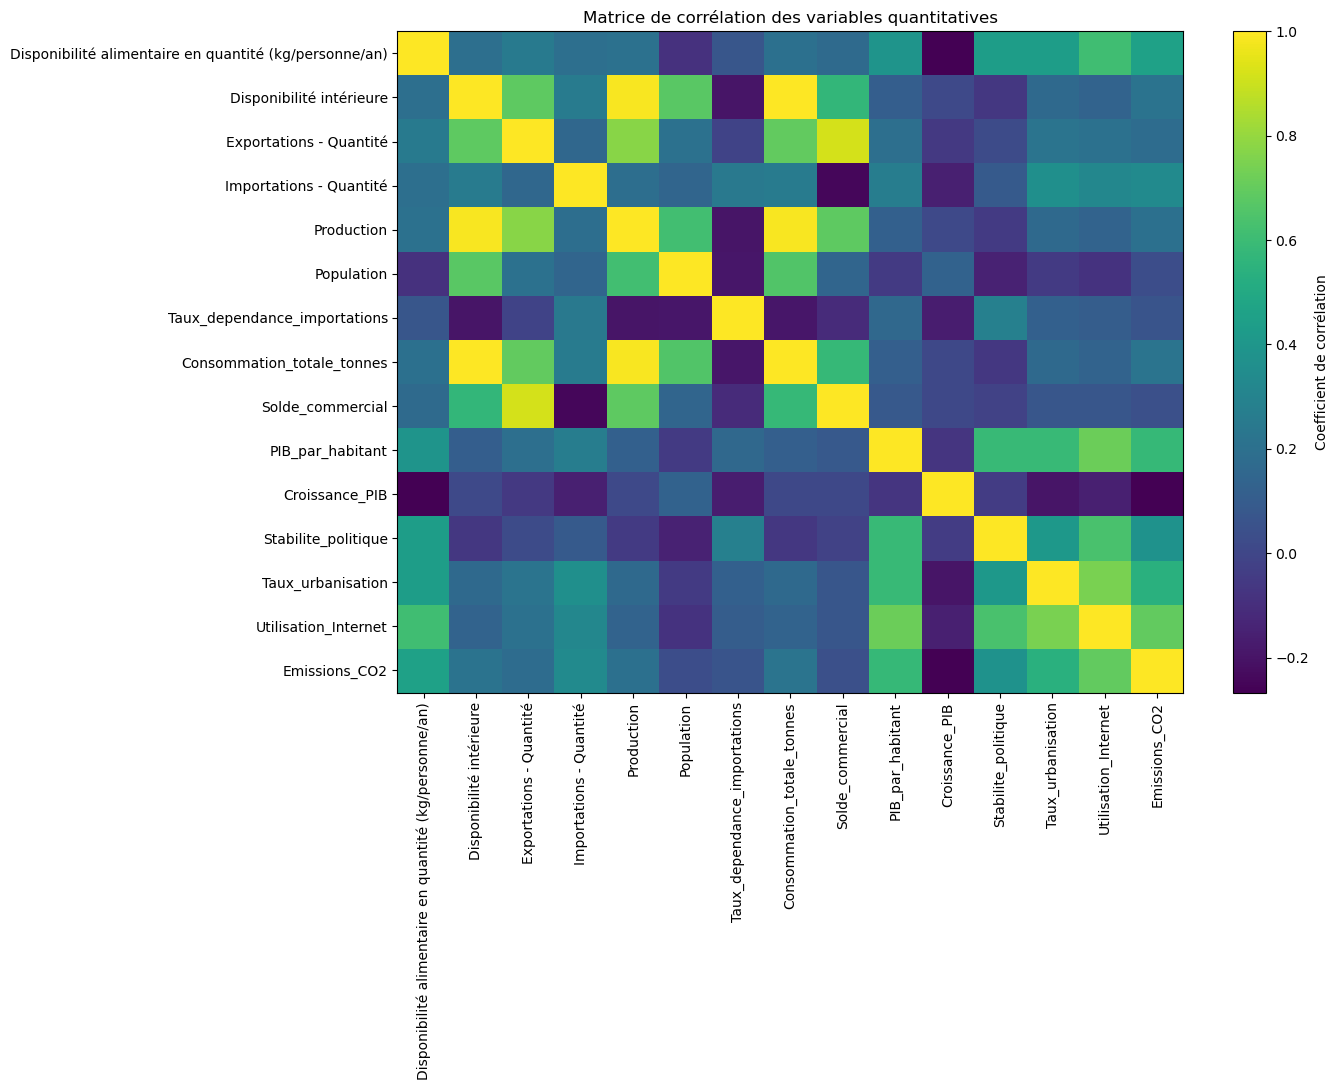

In [106]:
# Visualisation de la matrice de corrélation

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 11))

plt.imshow(matrice_correlation, aspect="auto")

plt.colorbar(label="Coefficient de corrélation")

plt.xticks(
    range(len(matrice_correlation.columns)),
    matrice_correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(matrice_correlation.index)),
    matrice_correlation.index
)

plt.title("Matrice de corrélation des variables quantitatives")

plt.tight_layout()
plt.show()

In [107]:
# Identification des fortes corrélations entre variables
# Seuil retenu : valeur absolue du coefficient >= 0.80

fortes_correlations = []

for i in range(len(matrice_correlation.columns)):
    for j in range(i + 1, len(matrice_correlation.columns)):
        
        variable_1 = matrice_correlation.columns[i]
        variable_2 = matrice_correlation.columns[j]
        coefficient = matrice_correlation.iloc[i, j]
        
        if abs(coefficient) >= 0.80:
            fortes_correlations.append({
                "Variable_1": variable_1,
                "Variable_2": variable_2,
                "Correlation": coefficient
            })

fortes_correlations = pd.DataFrame(fortes_correlations)

if not fortes_correlations.empty:
    fortes_correlations["Correlation_absolue"] = (
        fortes_correlations["Correlation"].abs()
    )
    
    fortes_correlations = fortes_correlations.sort_values(
        "Correlation_absolue",
        ascending=False
    ).reset_index(drop=True)

print("Nombre de fortes corrélations détectées :", len(fortes_correlations))

display(
    fortes_correlations[
        ["Variable_1", "Variable_2", "Correlation"]
    ].round(3)
)

Nombre de fortes corrélations détectées : 4


,Variable_1,Variable_2,Correlation
0,Disponibilité intérieure,Consommation_totale_tonnes,0.999
1,Production,Consommation_totale_tonnes,0.989
2,Disponibilité intérieure,Production,0.988
3,Exportations - Quantité,Solde_commercial,0.920


### Interprétation des corrélations

L'analyse de la matrice de corrélation met en évidence **4 relations fortes**, avec un coefficient de corrélation absolu supérieur ou égal à 0,80.

Les corrélations les plus importantes concernent :

- la **disponibilité intérieure** et la **consommation totale** : **r = 0,999** ;
- la **production** et la **consommation totale** : **r = 0,989** ;
- la **disponibilité intérieure** et la **production** : **r = 0,988** ;
- les **exportations** et le **solde commercial** : **r = 0,920**.

Les trois premières relations montrent une forte proximité entre les variables décrivant les volumes alimentaires. Cette situation peut générer une **redondance d'information** dans les analyses multivariées.

La forte corrélation entre les exportations et le solde commercial s'explique également par leur proximité conceptuelle, le solde commercial étant directement lié aux flux d'importations et d'exportations.

Ces corrélations ne constituent pas des erreurs de données. Elles seront prises en compte dans la suite de l'analyse, notamment lors de la standardisation et de l'analyse en composantes principales (ACP).

**Décision : aucune variable n'est supprimée automatiquement à ce stade.**

## Export du jeu de données préparé pour le Notebook 2
Le jeu de données final complet est exporté afin d’être réutilisé directement pour l’ACP et le clustering.

In [ ]:
# Export du jeu de données préparé
data_analyse.to_csv("data_analyse_pret.csv", index=False, encoding="utf-8-sig")
print("Fichier exporté : data_analyse_pret.csv", data_analyse.shape)